# Predicting weekly bacterial abundance across years

Marine bacterial communities exhibit recurring annual patterns, but their responses to environmental conditions and seasonal transitions can vary between years (Ward et al., 2017). This notebook asks:

> **How accurately can weekly bacterial abundance be predicted across years and, after applying a training-derived cutoff, classified as Low or High? Do continuous periodic features and environmental measurements improve performance relative to a four-season baseline?**

Regression is used first to predict continuous log10 bacterial abundance, preserving information about the magnitude of differences between samples. The predictions are then converted into Low or High classes using a cutoff calculated from the training data. This provides a simpler description of abundance state while retaining a continuous prediction for model evaluation.

The dataset contains 151 approximately weekly samples from three years, including bacterial abundance and associated physical and biogeochemical measurements. Years 1 and 3 form the main training set, while Year 2 is held out for evaluation. Additional tests rotate the held-out year to examine interannual variation in model performance.


In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    mean_absolute_error,
    roc_auc_score,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.svm import SVC, SVR
from sklearn.compose import ColumnTransformer
from scipy.stats import ks_2samp
from sklearn.metrics import pairwise_distances

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 16
sns.set_palette('muted')

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/"
    "refs/heads/main/PIDweekly_env_data.txt"
)
bacteria = pd.read_csv(DATA_URL, sep=r"\s+")

### Feature preparation

The continuous `YearDay` variable is separated into sampling year and day of year. Bacterial abundance is log-transformed, ammonium is converted from nM to µM(The dataset description and parameter can be found at https://www.bco-dmo.org/dataset/956182), and dissolved inorganic nitrogen is calculated as ammonium plus nitrite and nitrate. Seasonal categories and periodic sine/cosine features provide two alternative representations of annual timing.

In [3]:
season_order = ["spring", "summer", "autumn", "winter"]
bacteria["Year"] = ((bacteria["YearDay"] - 1) // 365) + 1
bacteria["DayOfYear"] = ((bacteria["YearDay"] - 1) % 365) + 1
bacteria["LogAbundance"] = np.log10(bacteria["Bacteria_abundance"])
bacteria["NH4_uM"] = bacteria["NH4"] / 1000 # make it uM from nM according https://www.bco-dmo.org/dataset/956182 
# Dissolved Inorganic Nitrogen (DIN)# chemical notes: DIN = NH4 + NO2 + NO3
bacteria["DIN"] = bacteria["NH4_uM"] + bacteria["NO2.NO3"]
# winter = DecJanFeb, spring = MarAprMay, summer = JunJulAug, autumn = SepOctNov from the data_scrap.ipynb
season_conditions = [
    bacteria["DayOfYear"].between(60, 151),
    bacteria["DayOfYear"].between(152, 243),
    bacteria["DayOfYear"].between(244, 334),
]
bacteria["Season"] = pd.Categorical(
    np.select(season_conditions, season_order[:3], default="winter"),
    categories=season_order,
    ordered=True,
)
# finer harmonic features for day of year
for harmonic in range(1, 17):
    angle = 2 * np.pi * harmonic * (bacteria["DayOfYear"] - 1) / 365
    bacteria[f"Day_sin_{harmonic}"] = np.sin(angle)
    bacteria[f"Day_cos_{harmonic}"] = np.cos(angle)

for feature in ["Chlorophyll", "NH4_uM", "NO2.NO3", "PO4", "SiO4", "DIN", "DIC"]:
    bacteria[f"Log1p_{feature}"] = np.log1p(bacteria[feature].clip(lower=0))

## 1. EDA: evidence for the model design

The EDA focuses on four decisions: transform the target, represent annual timing continuously, and expect some year-to-year transfer difficulty and environmental features selection.

### 1.1 Transformation of the target

In [4]:
# Main split and training-derived classification threshold
main_training_mask = bacteria["Year"].isin([1, 3])
main_testing_mask = bacteria["Year"].eq(2)
main_cutoff = bacteria.loc[main_training_mask, "LogAbundance"].mean()
bacteria["MainTarget"] = (bacteria["LogAbundance"] > main_cutoff).astype(int)
quality_summary = pd.DataFrame({
    "Rows": [len(bacteria)],
    "Duplicate SampleID": [bacteria["SampleID"].duplicated().sum()],
    "Missing predictor values": [bacteria.drop(
        columns=["SampleID", "Bacteria_abundance"]
    ).isna().sum().sum()],
    "Years": [bacteria["Year"].nunique()],
})

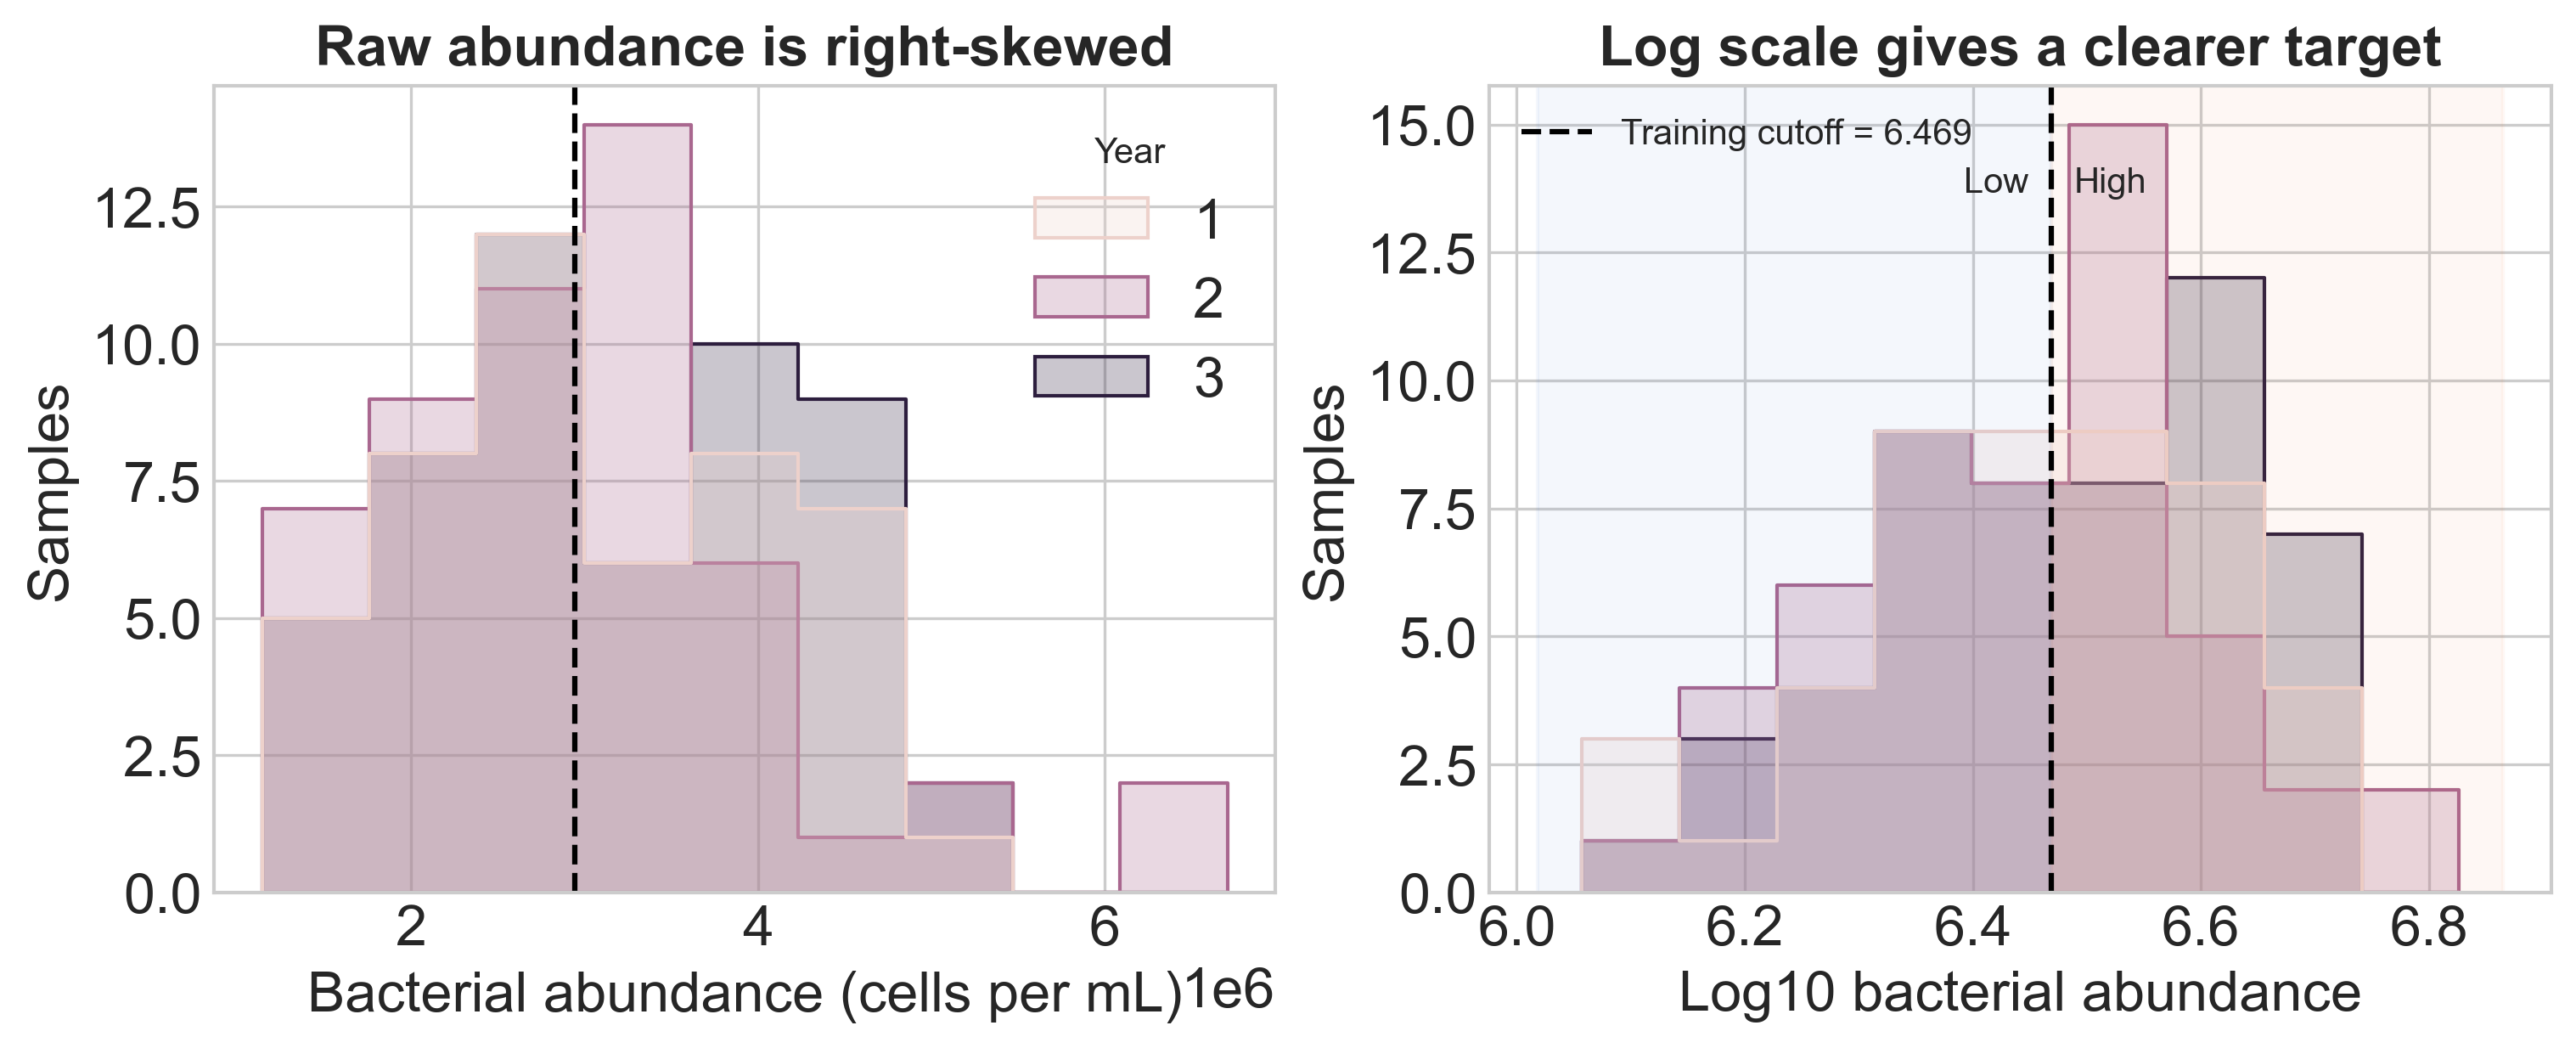

,Role,Years,N,Low,High
0,Training,1 and 3,99,46,53
1,Held-out Year 2,2,52,26,26


Equivalent raw cutoff: 2,944,772 cells mL⁻¹


In [5]:
#Plotting distributions of raw and log-transformed bacterial abundance
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
sns.histplot(
    data=bacteria, x="Bacteria_abundance", hue="Year",
    element="step", bins=9, common_norm=False, alpha=0.25, ax=axes[0],
)
axes[0].axvline(10 ** main_cutoff, color="black", linestyle="--", label="Cutoff")
axes[0].set(
    title="Raw abundance is right-skewed",
    xlabel="Bacterial abundance (cells per mL)",
    ylabel="Samples",
)
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(6, 6))

sns.histplot(
    data=bacteria, x="LogAbundance", hue="Year",
    element="step", bins=9, common_norm=False, alpha=0.25, ax=axes[1],
)
left_limit, right_limit = axes[1].get_xlim()
axes[1].axvspan(left_limit, main_cutoff, color=sns.color_palette()[0], alpha=0.06)
axes[1].axvspan(main_cutoff, right_limit, color=sns.color_palette()[1], alpha=0.06)
axes[1].axvline(
    main_cutoff, color="black", linestyle="--",
    label=f"Training cutoff = {main_cutoff:.3f}",
)
axes[1].text(main_cutoff - 0.02, axes[1].get_ylim()[1] * 0.90, "Low",
             ha="right", va="top")
axes[1].text(main_cutoff + 0.02, axes[1].get_ylim()[1] * 0.90, "High",
             ha="left", va="top")
axes[1].set(
    title="Log scale gives a clearer target",
    xlabel="Log10 bacterial abundance",
    ylabel="Samples",
)
axes[1].legend(fontsize=10)
plt.show()

class_summary = pd.DataFrame({
    "Role": ["Training", "Held-out Year 2"],
    "Years": ["1 and 3", "2"],
    "N": [main_training_mask.sum(), main_testing_mask.sum()],
    "Low": [
        bacteria.loc[main_training_mask, "MainTarget"].eq(0).sum(),
        bacteria.loc[main_testing_mask, "MainTarget"].eq(0).sum(),
    ],
    "High": [
        bacteria.loc[main_training_mask, "MainTarget"].eq(1).sum(),
        bacteria.loc[main_testing_mask, "MainTarget"].eq(1).sum(),
    ],
})
display(class_summary)
print(f"Equivalent raw cutoff: {10 ** main_cutoff:,.0f} cells mL⁻¹")

**Implication.** Target are set on log10 abundance so very large counts do not dominate the fit. Thus, log-transform chosen to be one of the pre-processing steps. The dashed line is the only cutoff used by every model in the main experiment: High is strictly above it; Low is at or below it. 

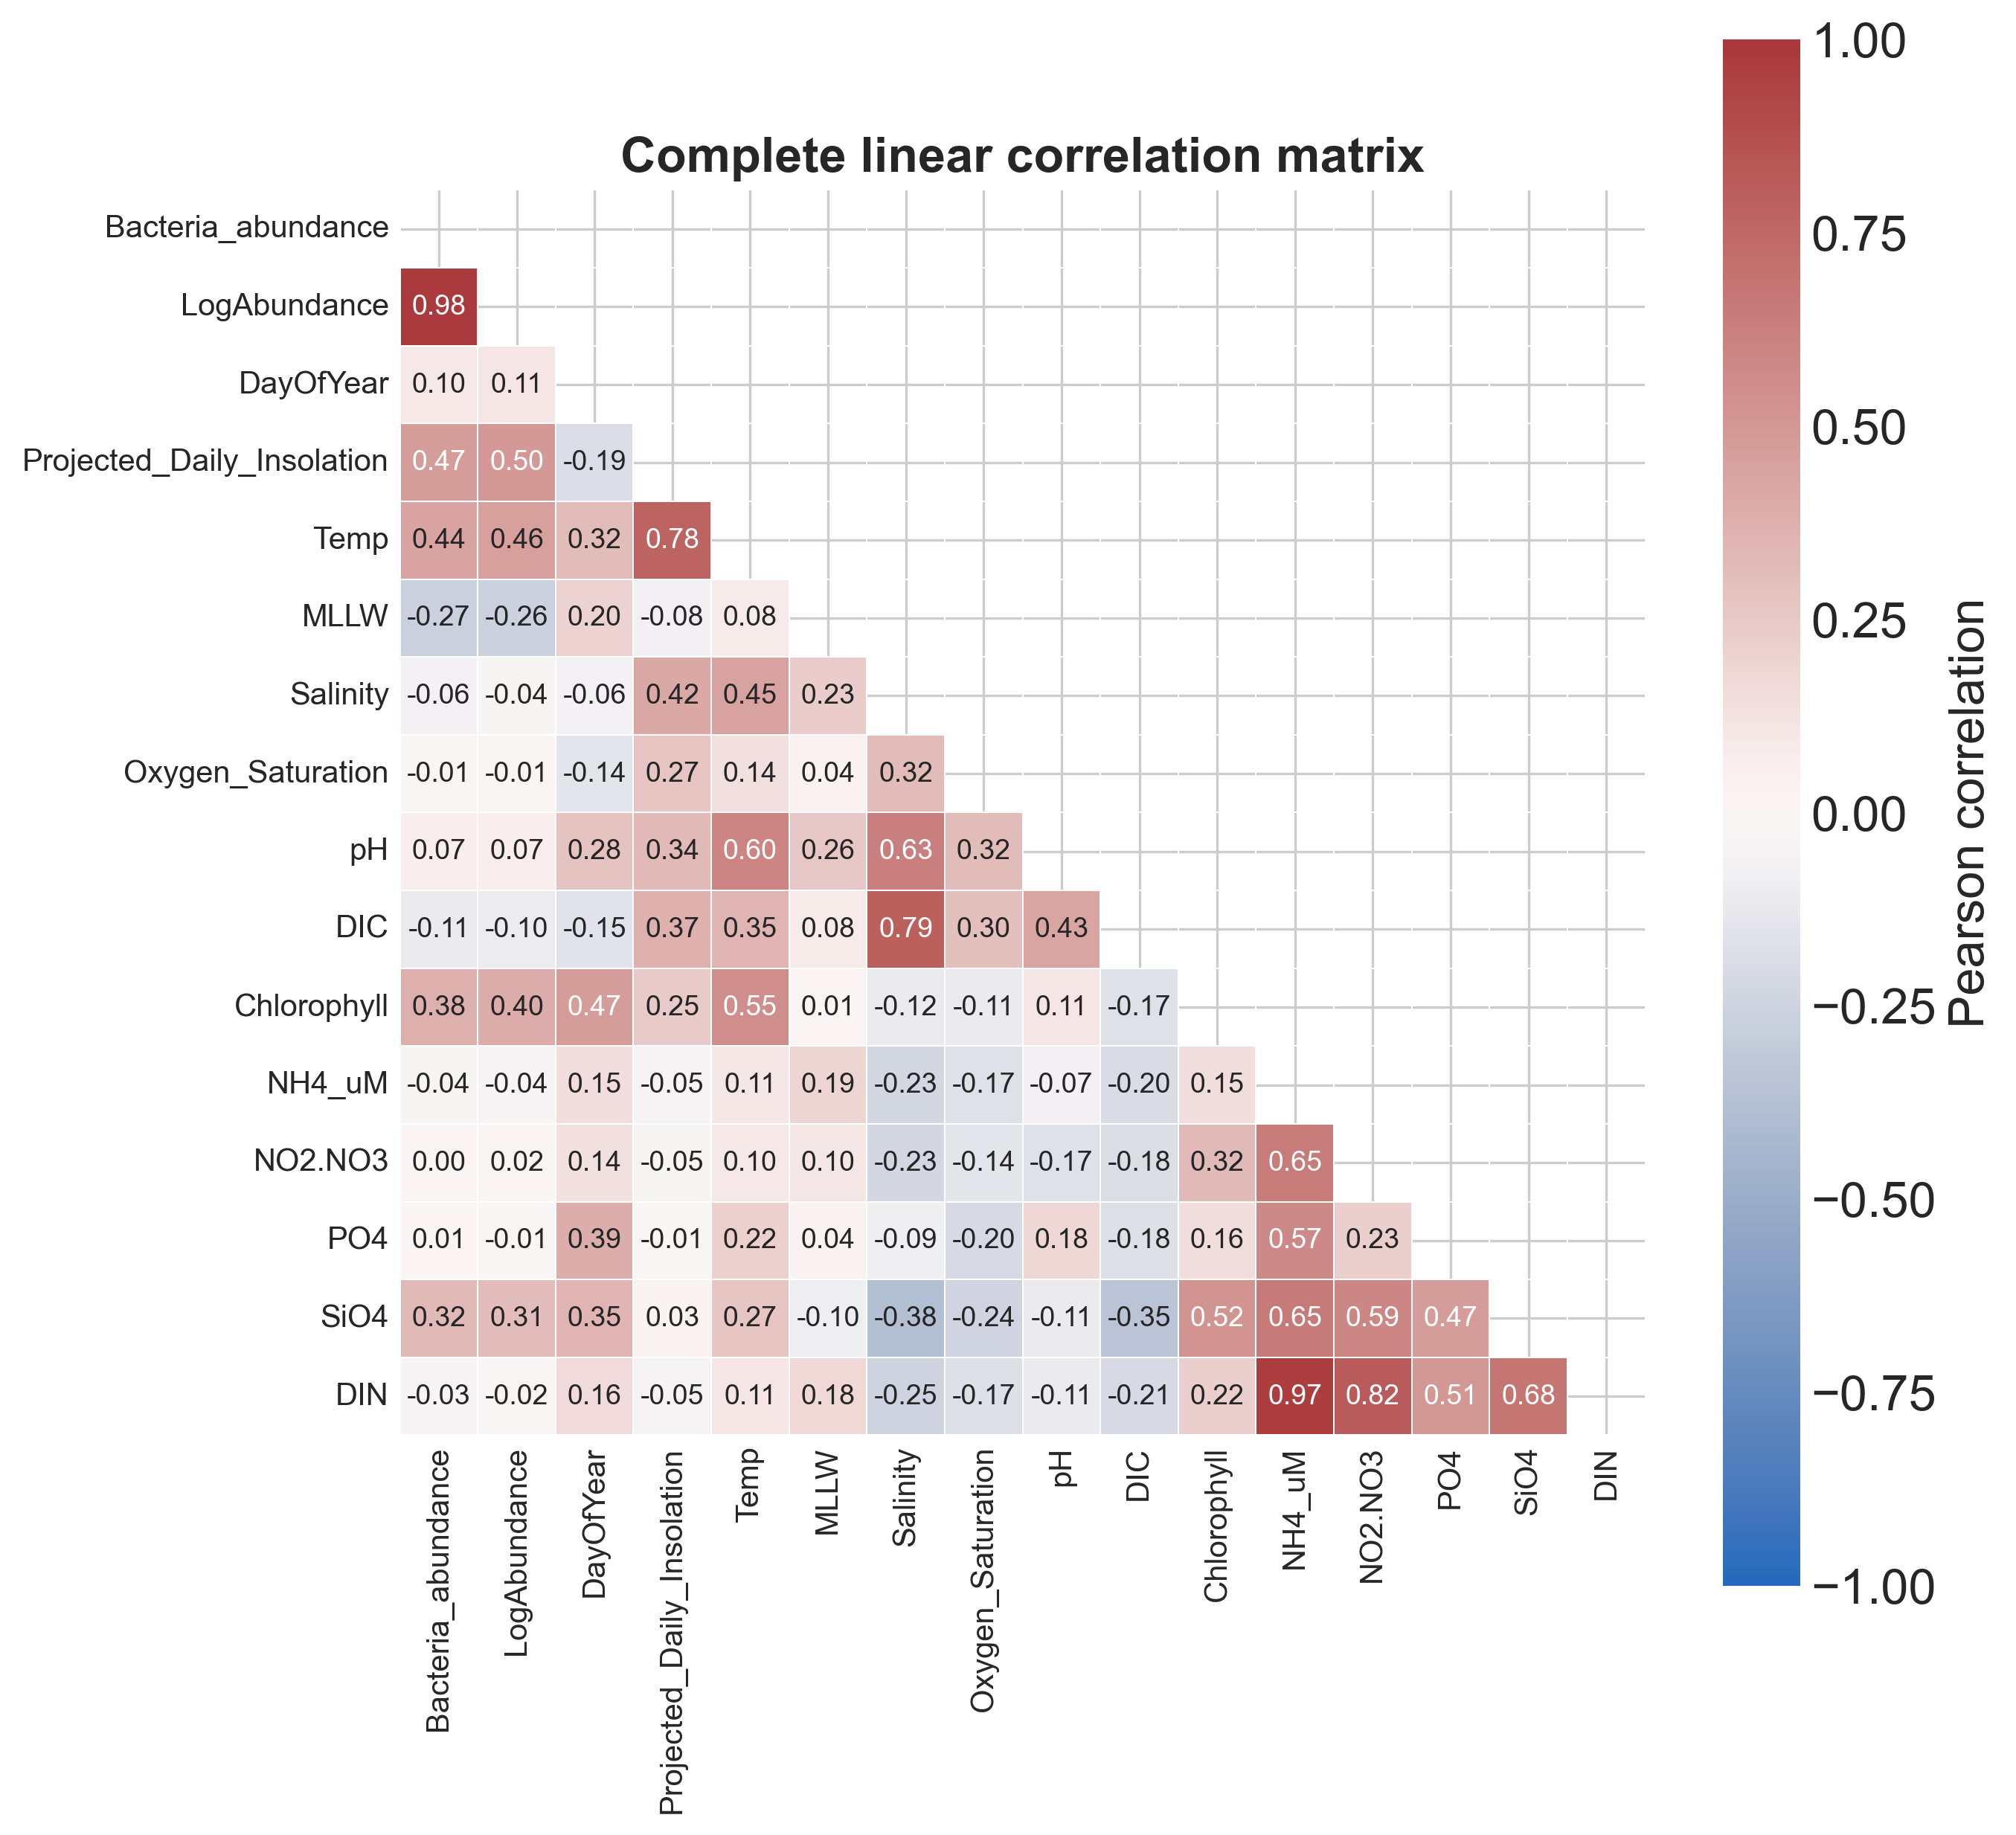

In [6]:
#plot correlation matrix to see features correlation with log10 abundance
correlation_columns = [
    "Bacteria_abundance", "LogAbundance", "DayOfYear",
    "Projected_Daily_Insolation", "Temp", "MLLW", "Salinity",
    "Oxygen_Saturation", "pH", "DIC", "Chlorophyll",
    "NH4_uM", "NO2.NO3", "PO4", "SiO4","DIN"
]
correlation_matrix = bacteria[correlation_columns].corr(method="pearson")
figure, axis = plt.subplots(figsize=(9, 9))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix, mask=mask, cmap="vlag", center=0,vmin=-1, vmax=1, square=True, linewidths=0.4,annot=True, fmt=".2f", annot_kws={"size": 9}, cbar_kws={"label": "Pearson correlation"}, 
    ax=axis,
)

axis.set_title("Complete linear correlation matrix")
axis.tick_params(axis="both", labelsize=10)
plt.show()

**Implication.** Time, physical conditions and chemistry overlap strongly, so unregularized coefficients would be unstable.

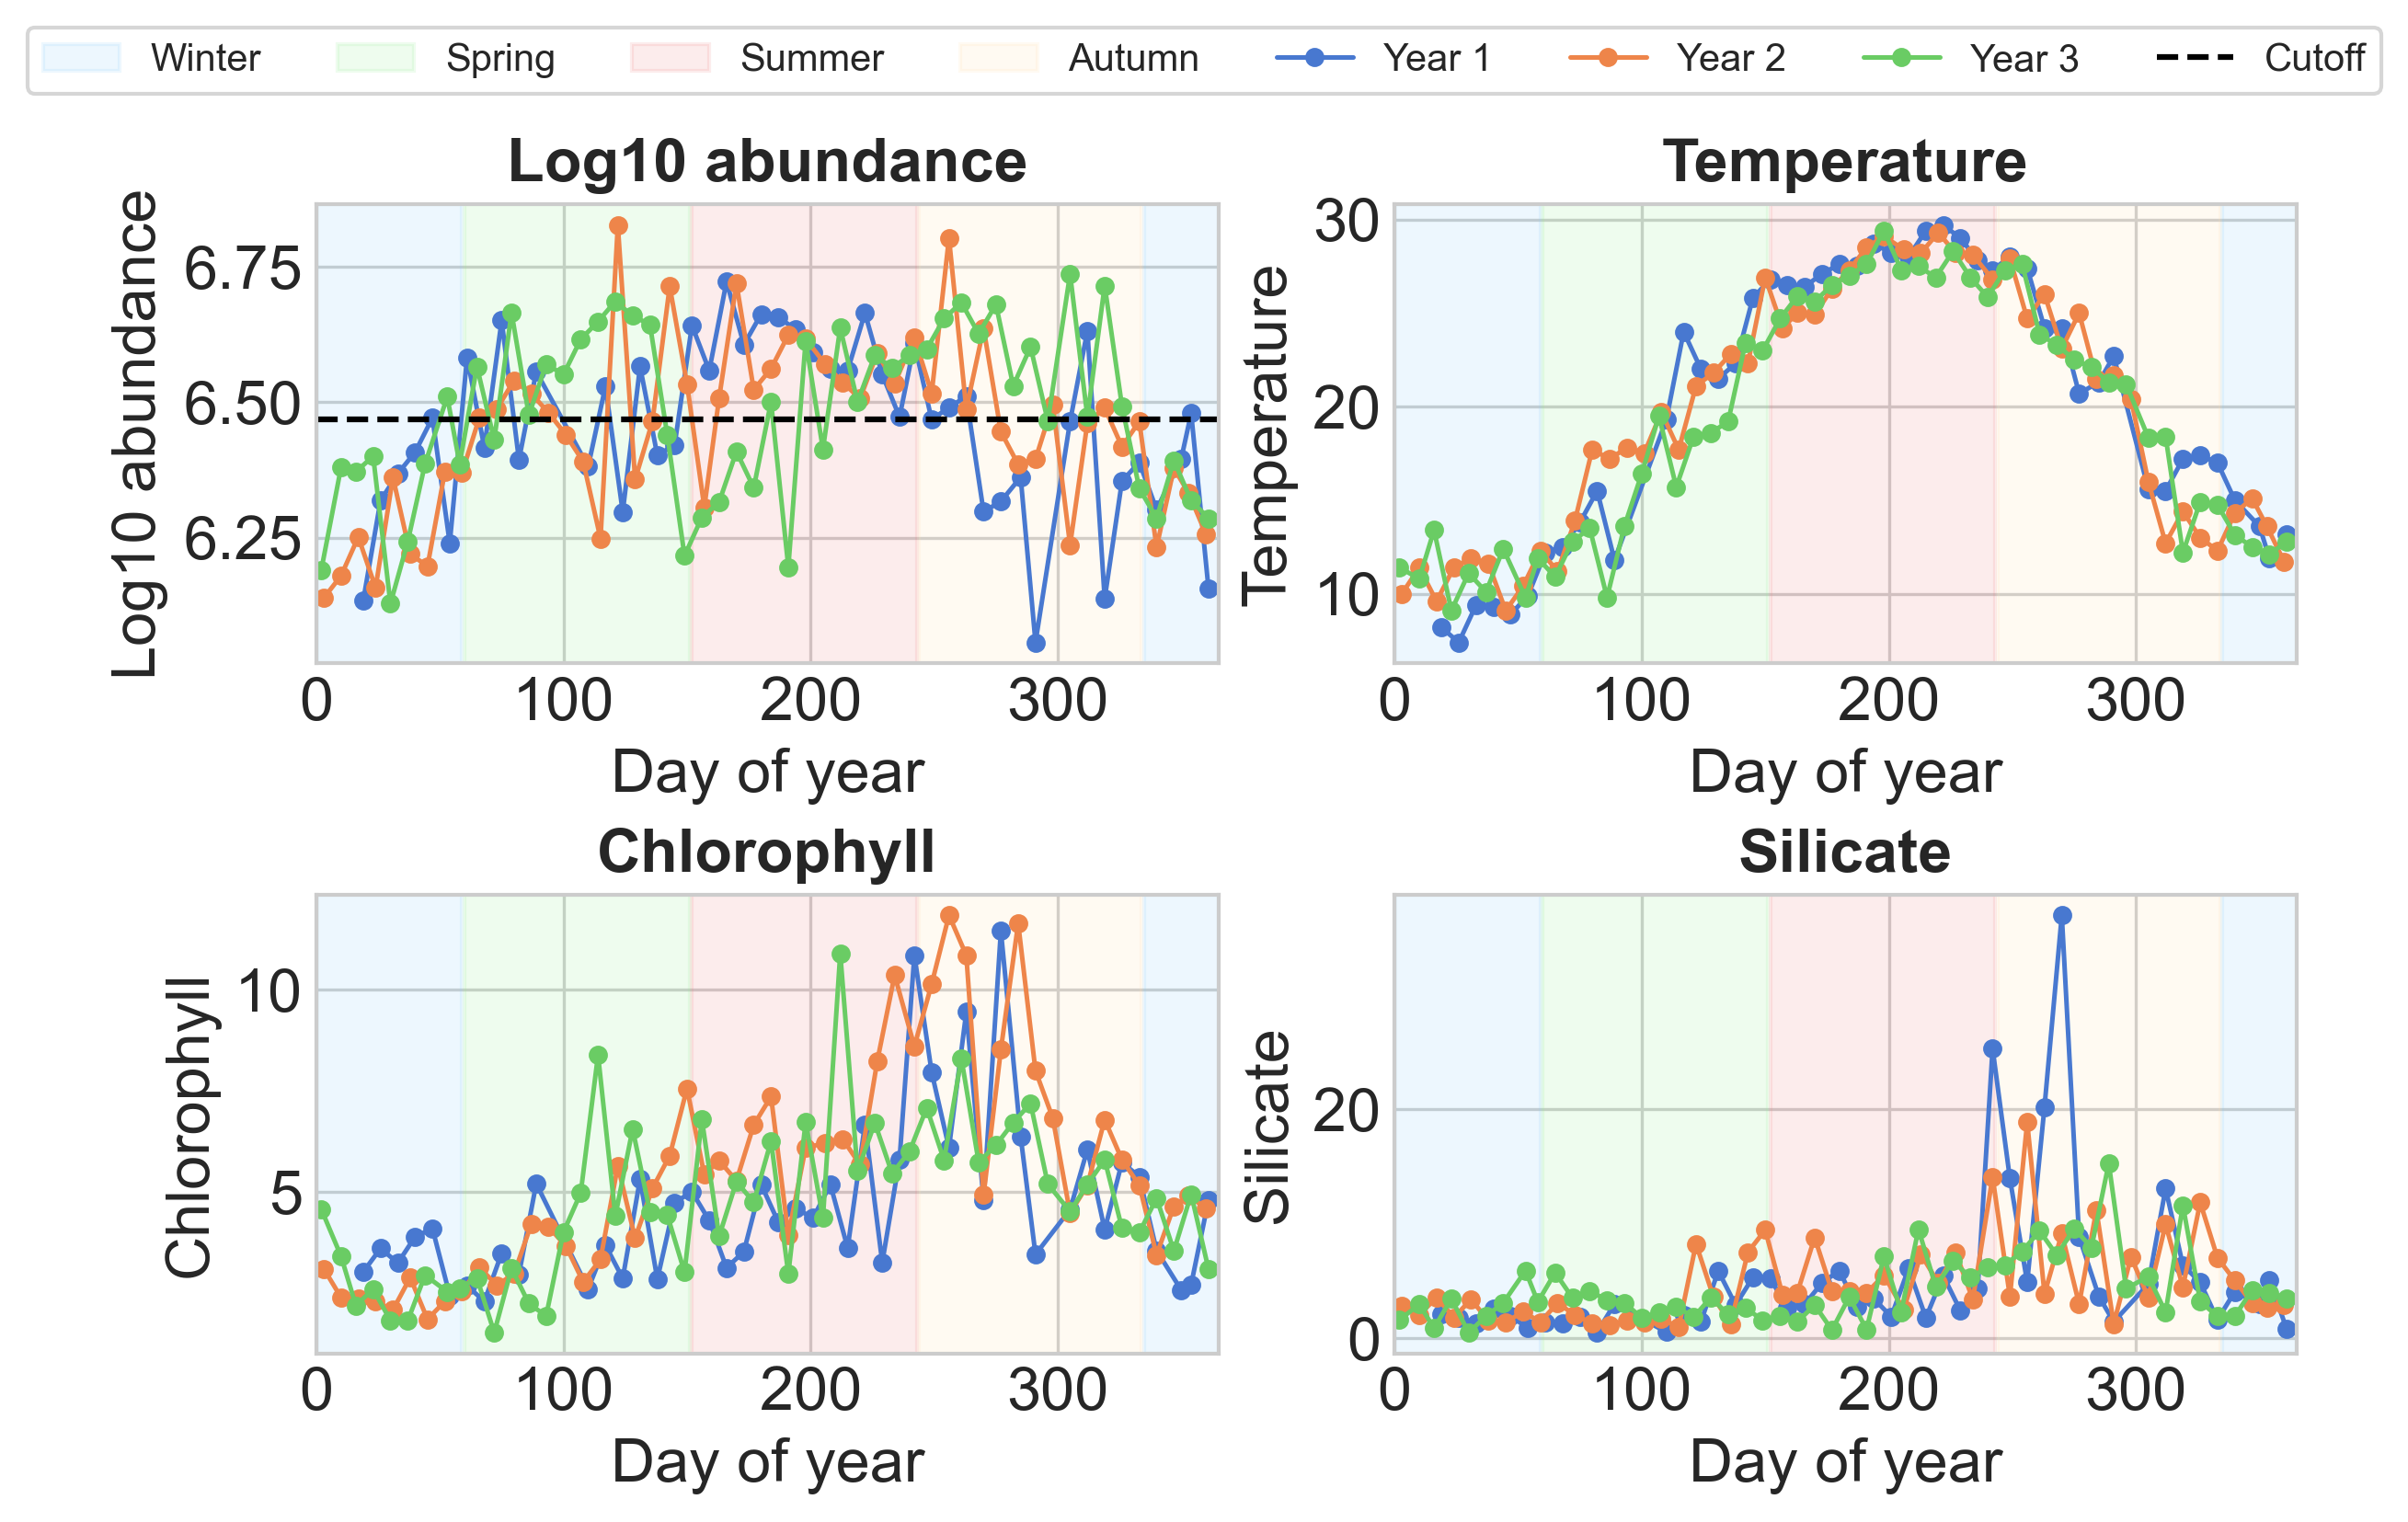

In [7]:
# Seasonal shading shared by the annual-cycle figures
seasons = [
    {"name": "Winter", "range": (0, 59), "color": "lightskyblue"},
    {"name": "Spring", "range": (60, 151), "color": "lightgreen"},
    {"name": "Summer", "range": (152, 243), "color": "lightcoral"},
    {"name": "Autumn", "range": (244, 334), "color": "navajowhite"},
    {"name": "Winter (End)", "range": (335, 365), "color": "lightskyblue"}
]

cycle_variables = {
    "LogAbundance": "Log10 abundance",
    "Temp": "Temperature",
    "Chlorophyll": "Chlorophyll",
    "SiO4": "Silicate",
}

figure, axes = plt.subplots(2, 2, figsize=(8, 5), constrained_layout=True)

for axis, (variable, label) in zip(axes.flat, cycle_variables.items()):
    for season in seasons:
        legend_label = season["name"] if variable == "LogAbundance" and "End" not in season["name"] else ""
        axis.axvspan(season["range"][0], season["range"][1], color=season["color"], alpha=0.15, label=legend_label)
    for year, yearly_data in bacteria.groupby("Year"):
        yearly_data = yearly_data.sort_values("DayOfYear")
        axis.plot(
            yearly_data["DayOfYear"], yearly_data[variable],
            marker="o", markersize=4, linewidth=1.2, label=f"Year {year}" if variable == "LogAbundance" else "",
        )
        
    if variable == "LogAbundance":
        axis.axhline(main_cutoff, color="black", linestyle="--", label="Cutoff")
        
    axis.set(title=label, xlabel="Day of year", ylabel=label)
    axis.set_xlim(0, 365)

handles, labels = axes[0, 0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
figure.legend(
    by_label.values(), 
    by_label.keys(), 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.01), 
    ncol=8, 
    fontsize=10, 
    frameon=True
)

plt.show()

**Implication.** The broad cycle of abundance, chlorophyll and temperature repeats, but its amplitude and transition timing change between years. Four season labels capture the broad pattern

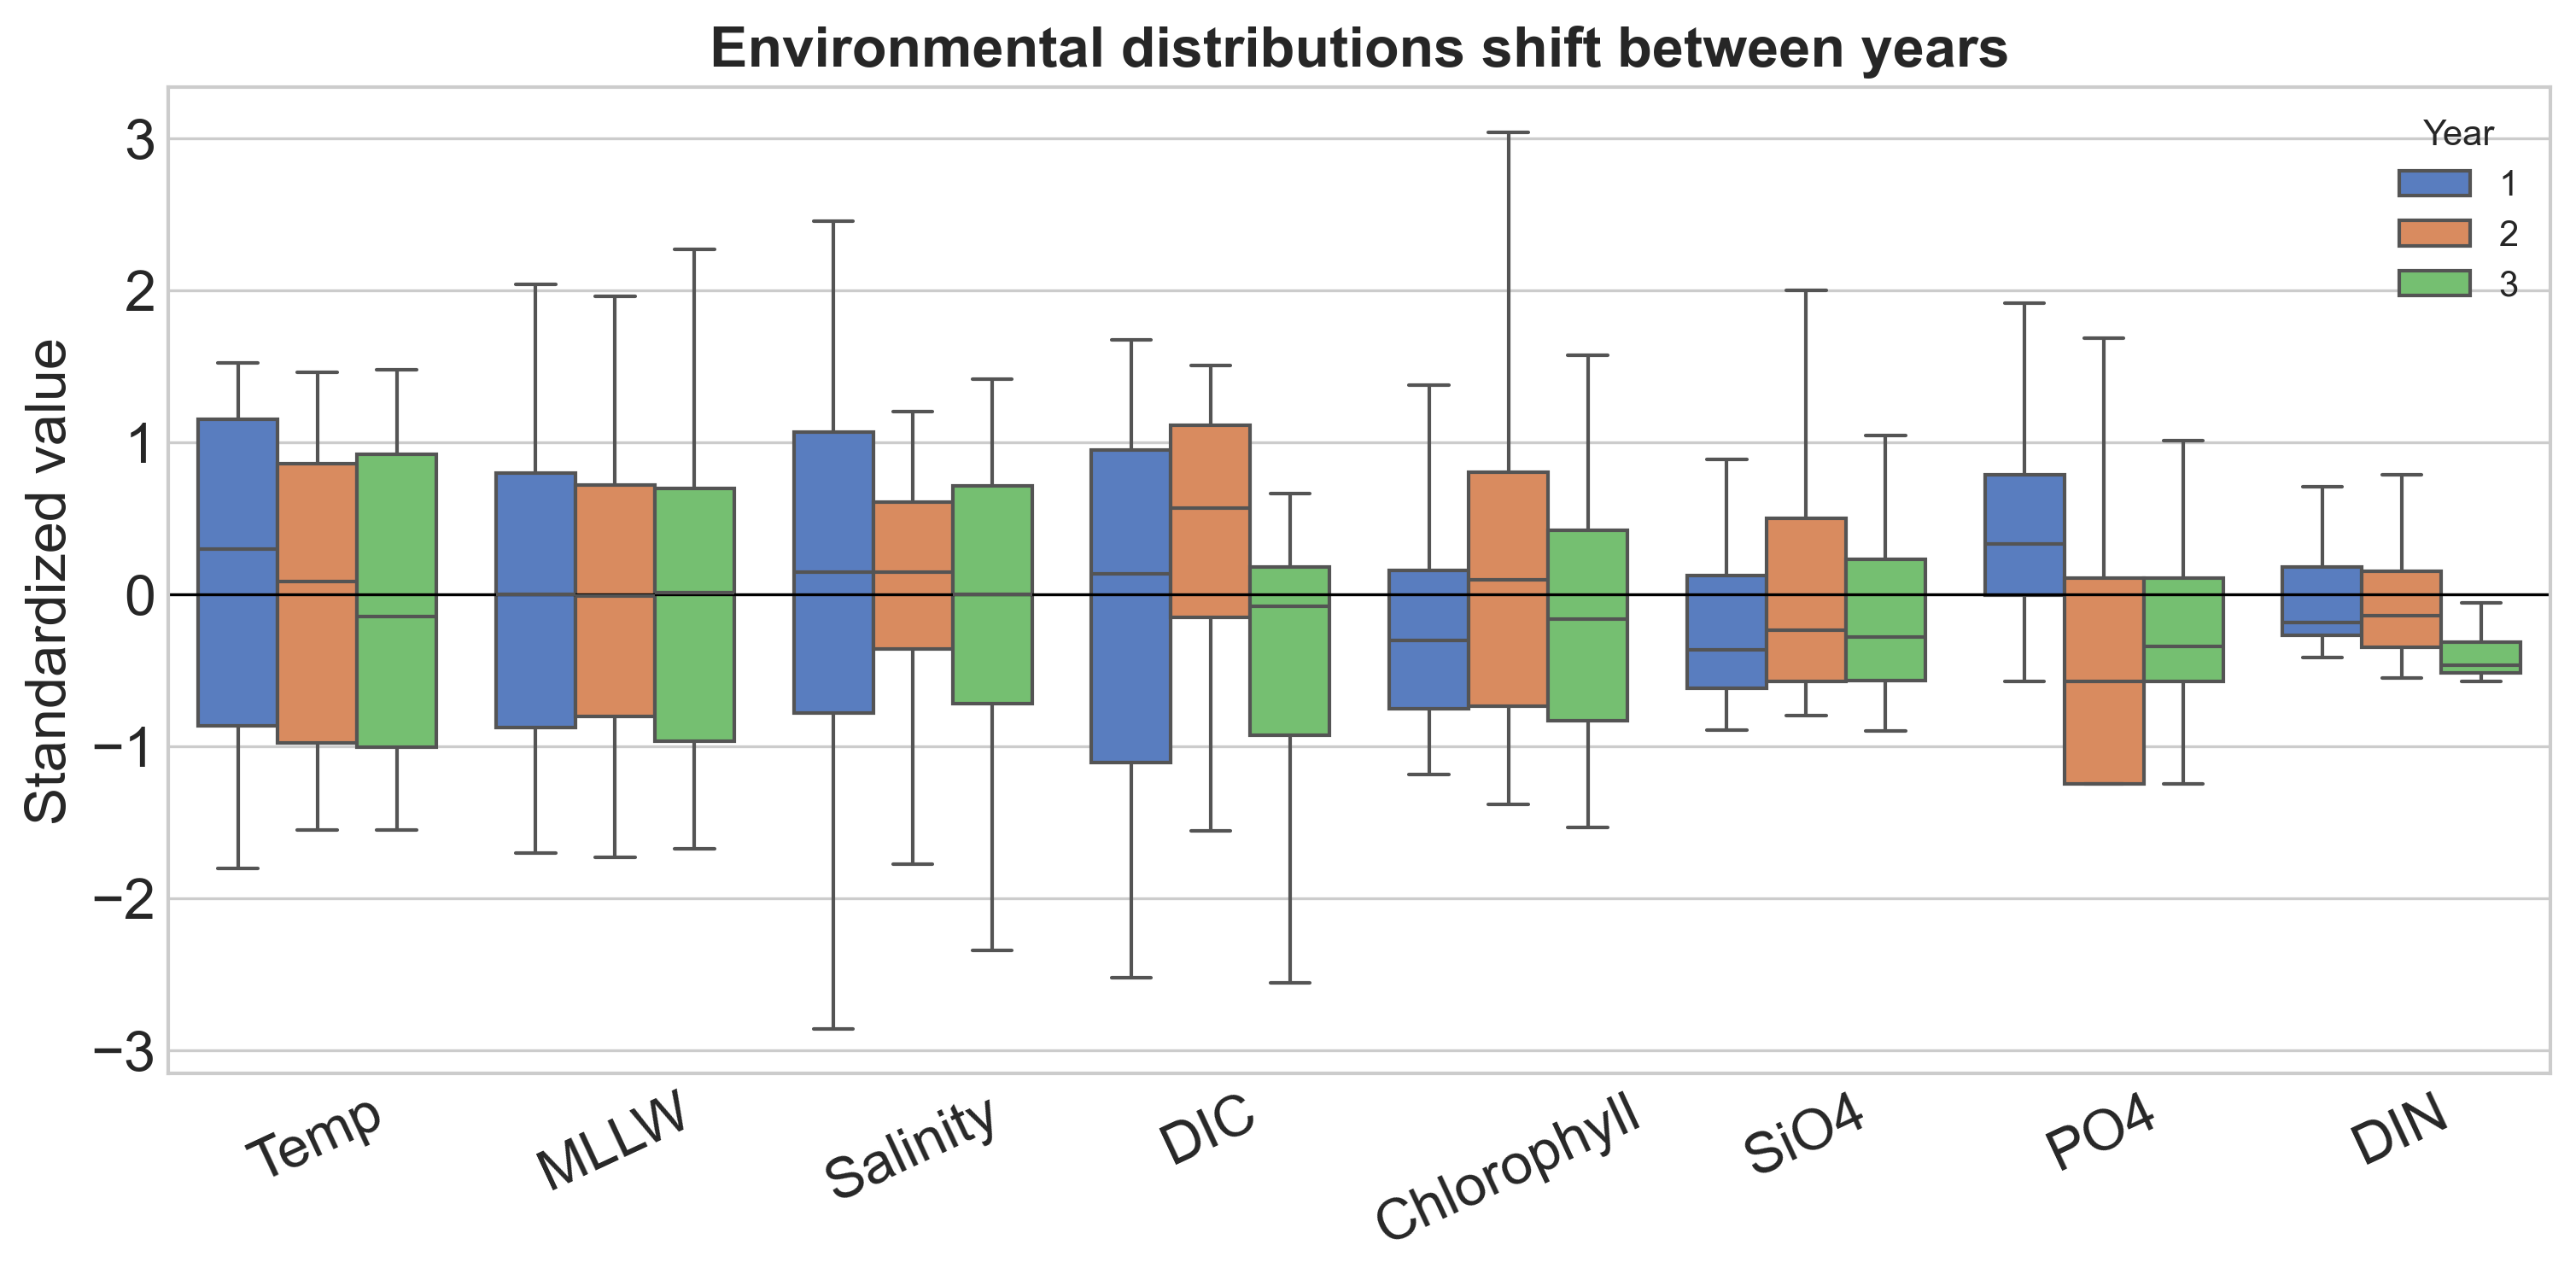

In [8]:
shift_features = [
    "Temp", "MLLW", "Salinity",
    "DIC", "Chlorophyll", "SiO4","PO4","DIN"
]
standardized_shift = bacteria[shift_features].apply(
    lambda column: (column - column.mean()) / column.std()
)
shift_plot_data = (
    standardized_shift.assign(Year=bacteria["Year"].astype(str))
    .melt(id_vars="Year", var_name="Feature", value_name="Standardized value")
)

figure, axis = plt.subplots(figsize=(12, 5))
sns.boxplot(
    data=shift_plot_data, x="Feature", y="Standardized value",
    hue="Year", showfliers=False, ax=axis,
)
axis.axhline(0, color="black", linewidth=0.8)
axis.set(title="Environmental distributions shift between years", xlabel="", ylabel="Standardized value")
axis.tick_params(axis="x", rotation=25)
axis.legend(title="Year", fontsize=10)
plt.show()

**Implication.**  The above final environmental features are selected due to their "similar distrubution" arcoss 3 years and their chemial and physical uniqueness. Others like Projected_Daily_Insolation, No2.No3 and NH4 are believed to be represented in the above features already. (Of course, the above combinations of the choices are also selected by hindsight from downstream prediction performance which the notebook do not explictly show. For example, pH and Oxygen_Saturation hinder the performance)

In [9]:
features = [ 'Bacteria_abundance',
       'Projected_Daily_Insolation', 'Temp', 'MLLW', 'Salinity',
       'Oxygen_Saturation', 'pH', 'DIC', 'Chlorophyll', 'NH4', 'NO2.NO3',]

distribution_shift_columns = [
    "DayOfYear",
    *features,
    "LogAbundance",  
]

sampling_years = sorted(bacteria["Year"].unique())
sampling_year_pairs = [
    (first_year, second_year)
    for year_index, first_year in enumerate(sampling_years)
    for second_year in sampling_years[year_index + 1:]
]

# Calculate Kolmogorov-Smirnov statistics, the higher the value, the more different the distributions are
distribution_shift_rows = []
for variable in distribution_shift_columns:
    for first_year, second_year in sampling_year_pairs:
        first_values = bacteria.loc[bacteria["Year"].eq(first_year), variable].dropna()
        second_values = bacteria.loc[bacteria["Year"].eq(second_year), variable].dropna()
        
        ks_result = ks_2samp(first_values, second_values, method="asymp")
        
        distribution_shift_rows.append({
            "variable": variable,
            "year_pair": f"Year {first_year} vs {second_year}",
            "ks_statistic": ks_result.statistic,
        })

distribution_shift_results = pd.DataFrame(distribution_shift_rows)
distribution_shift_matrix = distribution_shift_results.pivot(
    index="variable", columns="year_pair", values="ks_statistic"
)


maximum_shift_indices = distribution_shift_results.groupby("variable")["ks_statistic"].idxmax()
maximum_shift_summary = (
    distribution_shift_results.loc[maximum_shift_indices]
    .sort_values("ks_statistic", ascending=False)
    .reset_index(drop=True)
)

print("=== Maximum Distribution Shift per Variable ===")
display(maximum_shift_summary.round(3))

=== Maximum Distribution Shift per Variable ===


,variable,year_pair,ks_statistic
0,NH4,Year 1 vs 3,0.786
1,Oxygen_Saturation,Year 1 vs 3,0.633
2,DIC,Year 2 vs 3,0.481
3,NO2.NO3,Year 1 vs 2,0.414
4,pH,Year 1 vs 3,0.353
5,Salinity,Year 1 vs 3,0.283
6,Chlorophyll,Year 1 vs 2,0.230
7,Bacteria_abundance,Year 2 vs 3,0.212
8,LogAbundance,Year 2 vs 3,0.212
9,MLLW,Year 1 vs 3,0.144


**Implication.**  Rationale for Training on Year 1 and Year 3. EDA revealed severe inter-annual distribution shifts in critical biogeochemical markers. The Kolmogorov-Smirnov (KS) statistics (a reference probability distribution or whether two samples come from the same distribution) show the maximum divergence occurs between **Year 1 and Year 3** (e.g., `NH4` KS = 0.79, `Oxygen_Saturation` KS = 0.63). By deliberately selecting Years 1 and 3 as the primary training set, the models are exposed to the maximum possible variance and volatility in the ecosystem's chemical profile.

## 2. Experimental setup and selected models
**Data Shape & Validation Geometry**
The binary cutoff is dynamically derived from the training set's mean log-abundance. 

**2.1 Phase 1: Time Representation Baselines (No Abiotic Features)**
Initial models evaluate pure temporal inputs to determine the optimal architecture:
* **Inputs:** Categorical (`Season`) vs. Continuous (2 Fourier harmonics).
* **Models:** SVC (Direct Classification) vs. SVR (Regression thresholded to class).
* **Conclusion:** Continuous harmonics outperform categorical seasons, establishing regression-to-classification as the optimal pipeline.


**2.2 Phase 2: Time + Environmental Models**
(To prevent temporal leakage during hyperparameter tuning, inner validation uses **Year-CV** (`GroupKFold` grouped by `Year`). All imputation and scaling are strictly encapsulated within pipelines)
The finalized pipelines integrate 8 abiotic features (`Temp`, `MLLW`, `Salinity`, and log-transformed nutrients) with higher-frequency temporal waves:

| Model | Temporal Features | Env. Features | Task & Suitability |
| :--- | :--- | :--- | :--- |
| **Ridge** | 8 Harmonics (16 vars) | 8 variables | L2-regularized linear regression. Excels at tracking smooth, additive seasonal inertia. |
| **SVR (RBF)** | 8 Harmonics (16 vars) | 8 variables | Non-linear regression. Captures interactions between periodic timing and environmental conditions. |

### 2.1 Phase 1: time-representation baselines

The first comparison isolates the representation of time. SVC predicts the binary class directly, whereas SVR predicts log10 abundance before the common training-derived cutoff is applied. Each model is tested with either four seasonal categories or two Fourier harmonics.

In [10]:
# accuracy and R2 score for classification and regression models using season and continuous features
features_season = ["Season"]
features_continuous = ["Day_sin_1", "Day_cos_1", "Day_sin_2", "Day_cos_2"]
X_train = bacteria.loc[main_training_mask]
X_test = bacteria.loc[main_testing_mask]
y_train_class = bacteria.loc[main_training_mask, "MainTarget"]
y_test_class = bacteria.loc[main_testing_mask, "MainTarget"]
y_train_reg = bacteria.loc[main_training_mask, "LogAbundance"]
y_test_reg = bacteria.loc[main_testing_mask, "LogAbundance"]


pipe_svc_season = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(drop='first'), features_season)])),
    ('classifier', SVC(kernel='linear', random_state=42))
])

pipe_svc_cont = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), features_continuous)])),
    ('classifier', SVC(kernel='linear', random_state=42))
])

pipe_svr_season = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(drop='first'), features_season)])),
    ('regressor', SVR(kernel='rbf'))
])

pipe_svr_cont = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), features_continuous)])),
    ('regressor', SVR(kernel='rbf'))
])


pipe_svc_season.fit(X_train[features_season], y_train_class)
pipe_svc_cont.fit(X_train[features_continuous], y_train_class)
pipe_svr_season.fit(X_train[features_season], y_train_reg)
pipe_svr_cont.fit(X_train[features_continuous], y_train_reg)


acc_svc_season = accuracy_score(y_test_class, pipe_svc_season.predict(X_test[features_season]))
acc_svc_cont = accuracy_score(y_test_class, pipe_svc_cont.predict(X_test[features_continuous]))
pred_svr_season = pipe_svr_season.predict(X_test[features_season])
r2_svr_season = r2_score(y_test_reg, pred_svr_season)

acc_svr_season_thresh = accuracy_score(y_test_class, (pred_svr_season > main_cutoff).astype(int))
pred_svr_cont = pipe_svr_cont.predict(X_test[features_continuous])
r2_svr_cont = r2_score(y_test_reg, pred_svr_cont)

acc_svr_cont_thresh = accuracy_score(y_test_class, (pred_svr_cont > main_cutoff).astype(int))

# Compare direct classification with thresholded regression
comparison_df = pd.DataFrame({
    "Model Task": ["Classification (SVC)", "Classification (SVC)", "Regression (SVR)", "Regression (SVR)"],
    "Time Representation": ["Categorical (Season)", "Continuous (Harmonics)", "Categorical (Season)", "Continuous (Harmonics)"],
    "Target": ["MainTarget", "MainTarget", "LogAbundance", "LogAbundance"],
    "Classification Accuracy": [acc_svc_season, acc_svc_cont, acc_svr_season_thresh, acc_svr_cont_thresh],
    "Regression R2 Score": ["N/A", "N/A", r2_svr_season, r2_svr_cont]
})

display(comparison_df)

,Model Task,Time Representation,Target,Classification Accuracy,Regression R2 Score
0,Classification (SVC),Categorical (Season),MainTarget,0.750000,N/A
1,Classification (SVC),Continuous (Harmonics),MainTarget,0.807692,N/A
2,Regression (SVR),Categorical (Season),LogAbundance,0.750000,0.454438
3,Regression (SVR),Continuous (Harmonics),LogAbundance,0.807692,0.466214


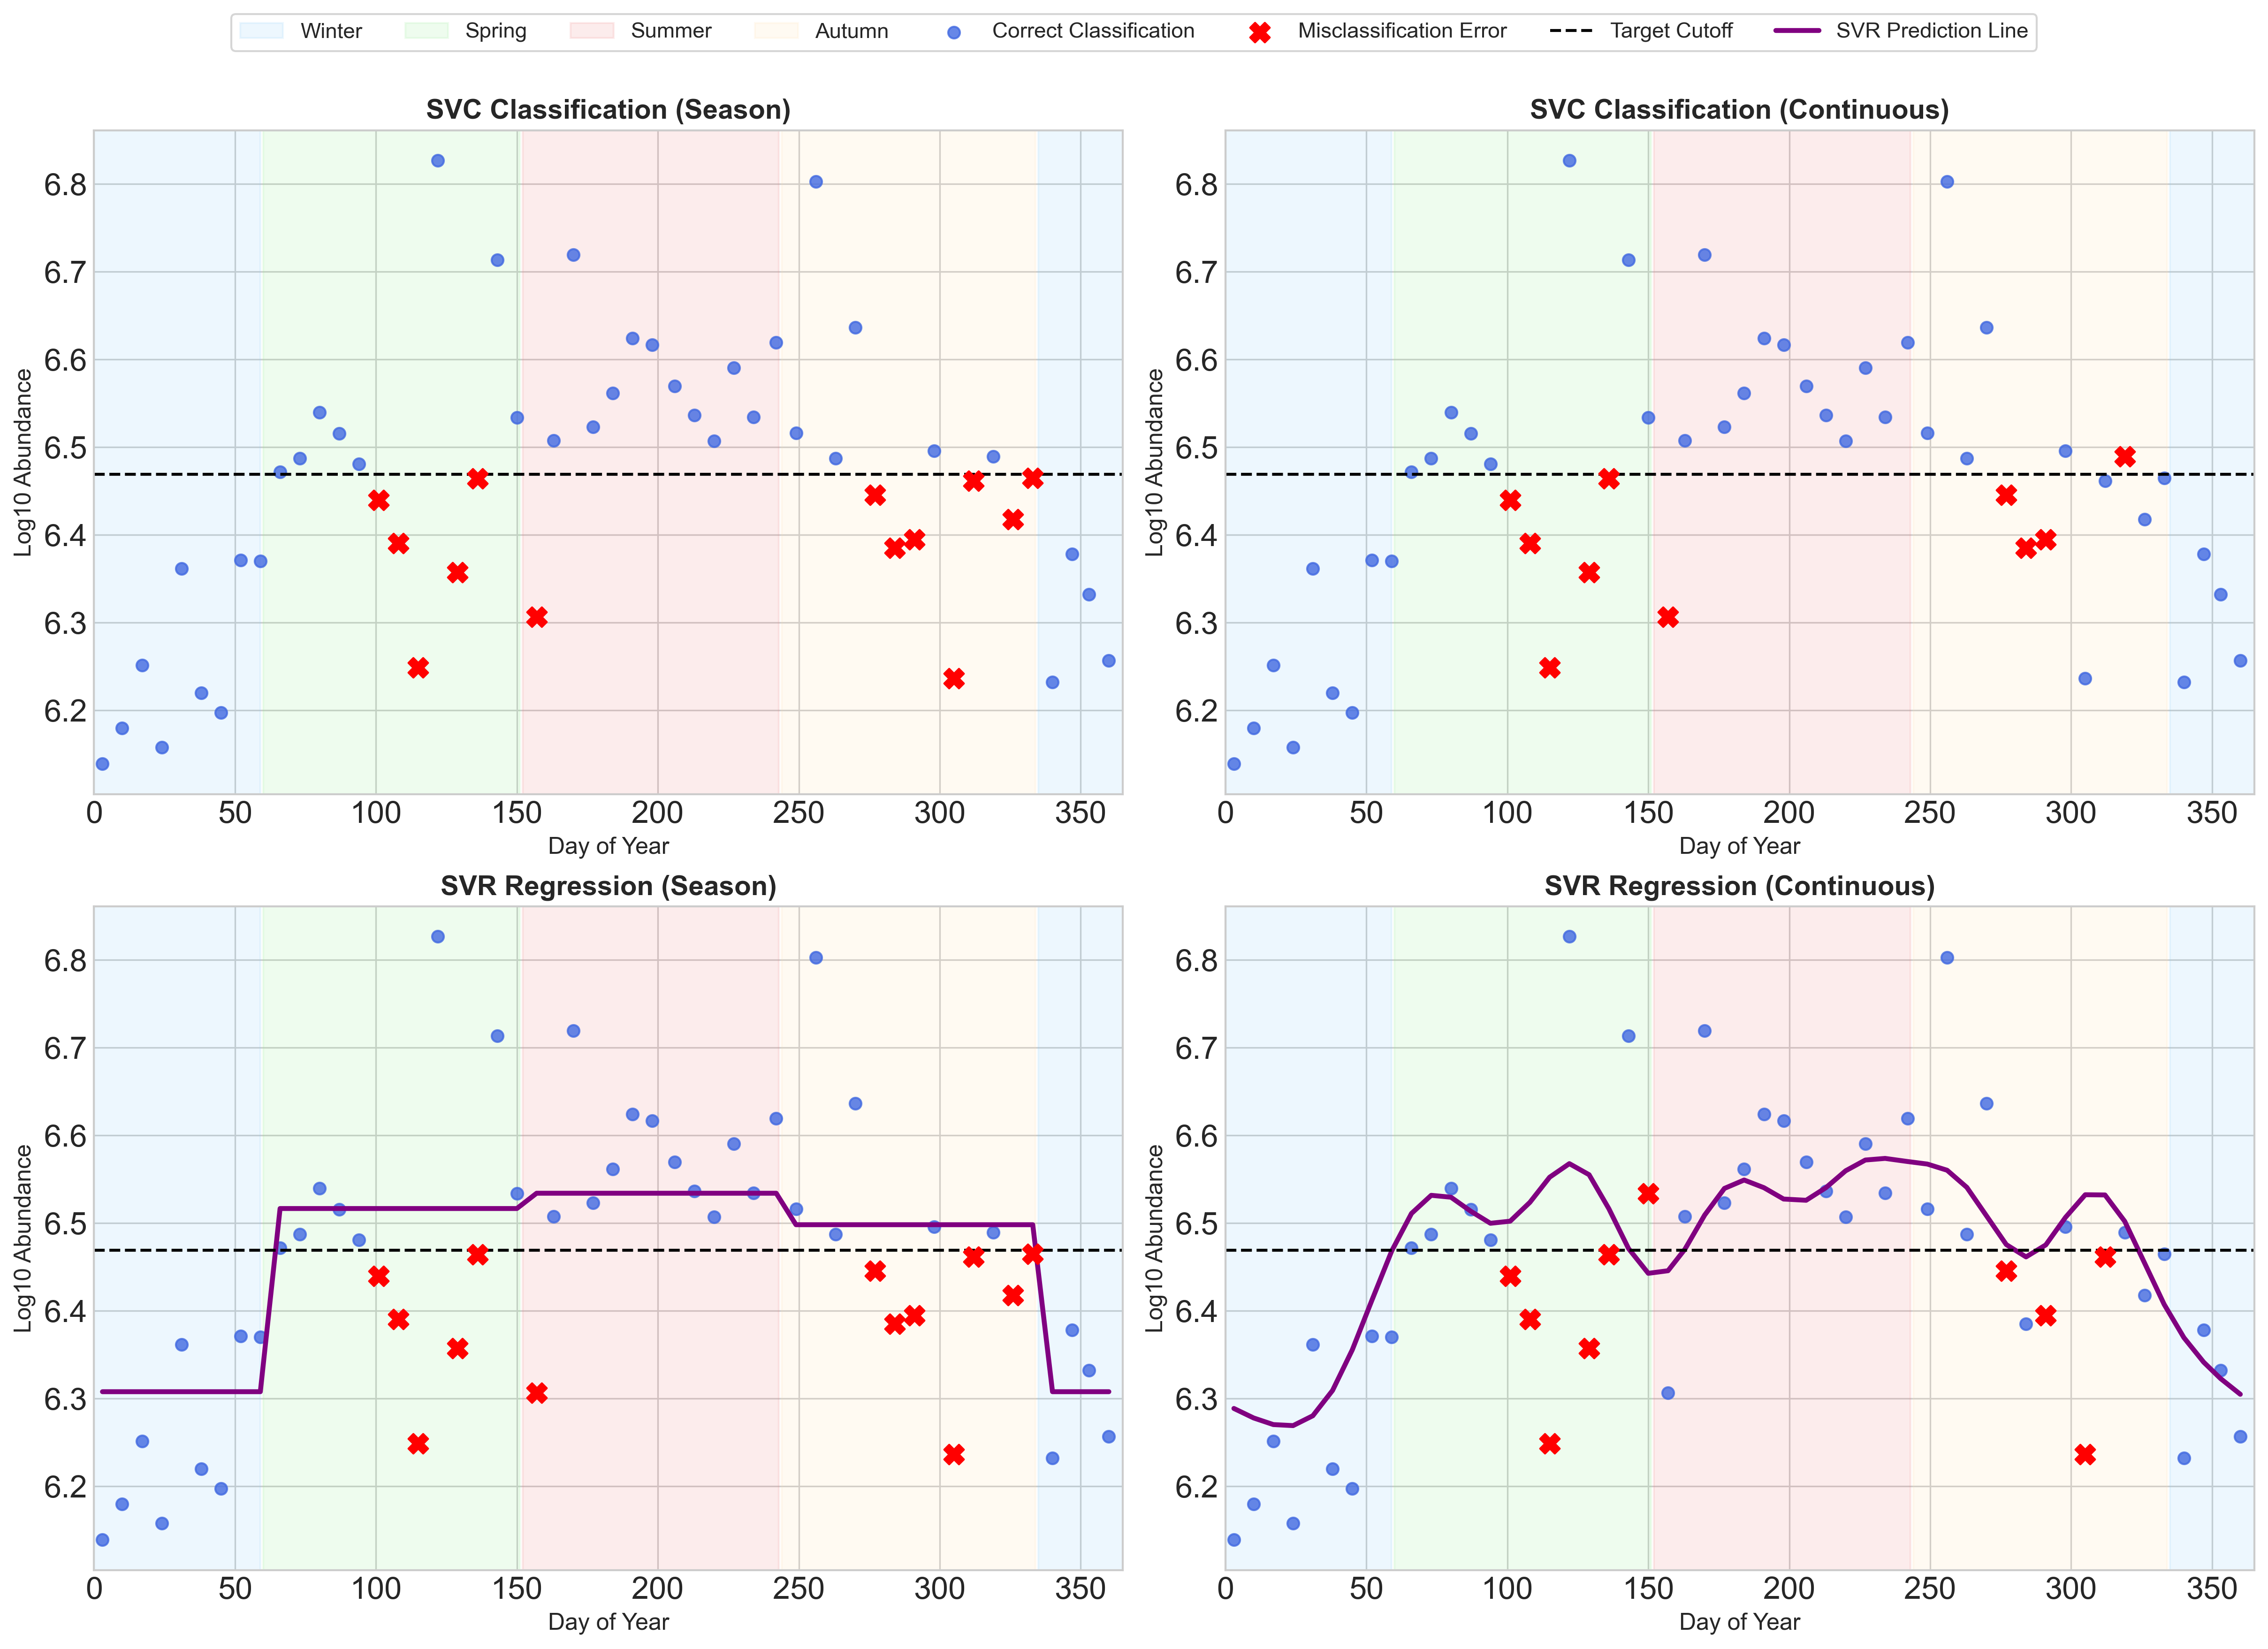

In [11]:
# Visualize model predictions and errors over the annual cycle
X_test = bacteria.loc[main_testing_mask].copy()
X_test["Pred_SVC_Season"] = pipe_svc_season.predict(X_test[features_season])
X_test["Pred_SVC_Cont"] = pipe_svc_cont.predict(X_test[features_continuous])
X_test["Pred_SVR_Season"] = pipe_svr_season.predict(X_test[features_season])
X_test["Pred_SVR_Cont"] = pipe_svr_cont.predict(X_test[features_continuous])

X_test["Err_SVC_Season"] = X_test["Pred_SVC_Season"] != X_test["MainTarget"]
X_test["Err_SVC_Cont"] = X_test["Pred_SVC_Cont"] != X_test["MainTarget"]
X_test["Err_SVR_Season"] = (X_test["Pred_SVR_Season"] > main_cutoff).astype(int) != X_test["MainTarget"]
X_test["Err_SVR_Cont"] = (X_test["Pred_SVR_Cont"] > main_cutoff).astype(int) != X_test["MainTarget"]
X_test = X_test.sort_values("DayOfYear")


models_to_plot = [
    ("SVC Classification (Season)", "Err_SVC_Season", None),
    ("SVC Classification (Continuous)", "Err_SVC_Cont", None),
    ("SVR Regression (Season)", "Err_SVR_Season", "Pred_SVR_Season"),
    ("SVR Regression (Continuous)", "Err_SVR_Cont", "Pred_SVR_Cont"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

for ax, (title, err_col, pred_col) in zip(axes.flat, models_to_plot):
    # Overlay Background Seasons
    for season in seasons:
        legend_label = season["name"] if "End" not in season["name"] else ""
        ax.axvspan(season["range"][0], season["range"][1], color=season["color"], alpha=0.15, label=legend_label)
        
    correct = X_test[~X_test[err_col]]
    errors = X_test[X_test[err_col]]
    
    ax.scatter(correct["DayOfYear"], correct["LogAbundance"], color="royalblue", alpha=0.8, marker="o", label="Correct Classification")
    ax.scatter(errors["DayOfYear"], errors["LogAbundance"], color="red", s=100, marker="X", zorder=5, label="Misclassification Error")
    
    # Plot SVR prediction curve if it's a regression model
    if pred_col:
        ax.plot(X_test["DayOfYear"], X_test[pred_col], color="purple", linestyle="-", linewidth=2.5, label="SVR Prediction Line")
        
    # Main target cutoff line
    ax.axhline(main_cutoff, color="black", linestyle="--", label="Target Cutoff")
    
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel("Day of Year", fontsize=12)
    ax.set_ylabel("Log10 Abundance", fontsize=12)
    ax.set_xlim(0, 365)

handles, labels = axes[0, 0].get_legend_handles_labels()
handles_svr, labels_svr = axes[1, 0].get_legend_handles_labels()
all_handles = handles + [h for h, l in zip(handles_svr, labels_svr) if l == "SVR Prediction Line"]
all_labels = labels + ["SVR Prediction Line"]

by_label = dict(zip(all_labels, all_handles))

fig.legend(
    by_label.values(), 
    by_label.keys(), 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.02), 
    ncol=8, 
    fontsize=11, 
    frameon=True
)

plt.show()

**Implication: Transitional Boundaries and the Shift to Continuous SVR**

The time-only ablation study reveals how much can be predicted from the calendar alone and finer temperal information can indeed improve model performance.

* **Seasonal Boundary Failures:** : Misclassifications cluster densely at seasonal transitions. The continuous harmonic representation of time models successfully smooth out these transitional boundaries.When only train with time featues, the continuous harmonic representation of time (sine/cosine) significantly outperforms seasonal categories (Accuracy: 0.807 vs 0.750) 
* **Transitioning to Environmental SVR:** The baseline results confirm that modeling the exact continuous `LogAbundance` via SVR establishes superior decision boundaries. To maximize predictive accuracy, the next logical step is to apply this robust SVR approach using the environmental feature setup. Ridge regression are also serve as a model for comparison.

### 2.2 Phase 2: time and environmental features

The second phase combines periodic timing with selected environmental predictors.

Hyperparameters are selected using two-fold `GroupKFold` cross-validation grouped by year. In each fold, the model is trained on one of the two training years and validated on the other, before their roles are reversed. `GridSearchCV` selects the SVR `C` and `gamma` values and the Ridge `alpha` value that produce the lowest mean validation MAE. The selected models are then refitted using both training years and evaluated on the held-out test year.

,Strategy,Prediction,Correct,N,Accuracy,Balanced accuracy,Log10 MAE,Selected parameters
0,Seasonal baseline,Class directly,39,52,0.750,0.750,NaN,None
1,Time-only SVR (Continuous Harmonics),Regression → class,42,52,0.808,0.808,0.086,Default (No Env Features)
2,Full-feature SVR,Regression → class,47,52,0.904,0.904,0.081,"C=0.3, gamma=0.005"
3,Year-CV periodic Ridge,Regression → class,47,52,0.904,0.904,0.082,alpha=100


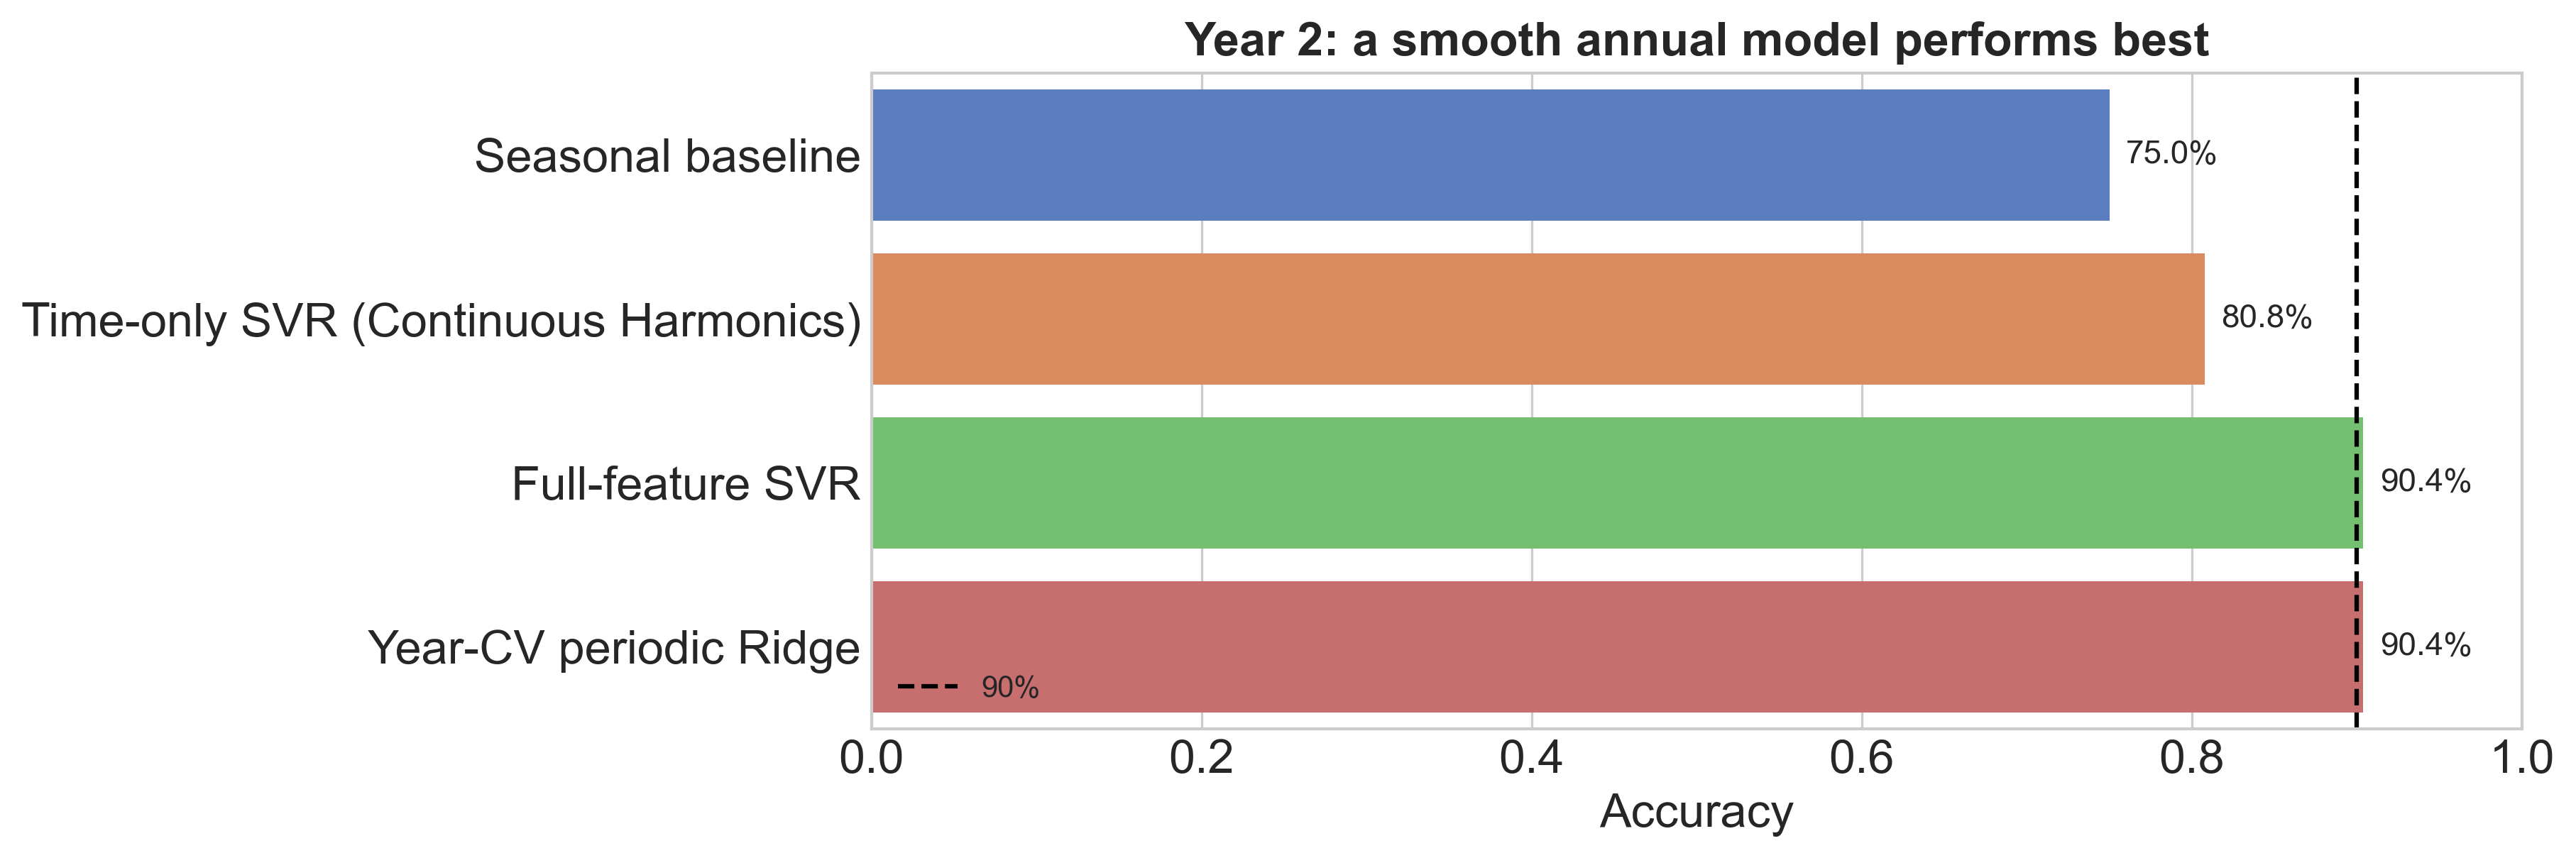

In [12]:
environmental_features = [
    "Temp", "MLLW", "Salinity",
    "Log1p_DIC", "Log1p_Chlorophyll",
     "Log1p_PO4", "Log1p_SiO4","Log1p_DIN"
]
svr_features = [
    name for harmonic in range(1, 9)
    for name in [f"Day_sin_{harmonic}", f"Day_cos_{harmonic}"] 
] + environmental_features

ridge_features = [
    name for harmonic in range(1, 9)
    for name in [f"Day_sin_{harmonic}", f"Day_cos_{harmonic}"]
] + environmental_features

def target_from_cutoff(data, cutoff):
    return (data["LogAbundance"] > cutoff).astype(int).to_numpy()

def seasonal_baseline(training_data, evaluation_data, training_target):
    season_rules = (
        pd.DataFrame({"Season": training_data["Season"], "Target": training_target})
        .groupby("Season", observed=False)["Target"]
        .agg(lambda values: int(values.mean() > 0.5))
    )
    overall_rule = int(np.mean(training_target) > 0.5)
    predictions = (
        evaluation_data["Season"].map(season_rules)
        .astype("float")
        .fillna(overall_rule)
        .astype(int)
        .to_numpy()
    )
    return predictions, season_rules

def regression_pipeline(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
        ("model", model),
    ])

def year_cv_search(model, parameter_grid):
    return GridSearchCV(
        regression_pipeline(model),
        parameter_grid,
        scoring="neg_mean_absolute_error",
        cv=GroupKFold(n_splits=2),
        n_jobs=-1,
    )

SVR_GRID = {
    "model__C": [0.3, 1, 3, 10, 30, 100],
    "model__gamma": ["scale", 0.005, 0.01, 0.05],
}
RIDGE_GRID = {"model__alpha": [0.01, 0.1, 1, 10, 100]}

def svr_cv_search():
    return year_cv_search(SVR(kernel="rbf"), SVR_GRID)

def ridge_cv_search():
    return year_cv_search(Ridge(), RIDGE_GRID)

def fit_regression_classifier(search, training, testing, features, cutoff):
    search.fit(
        training[features], training["LogAbundance"], groups=training["Year"]
    )
    log_predictions = search.predict(testing[features])
    return search, log_predictions, (log_predictions > cutoff).astype(int)

def classification_metrics(observed, predicted):
    return {
        "Correct": int((observed == predicted).sum()),
        "N": len(observed),
        "Accuracy": accuracy_score(observed, predicted),
        "Balanced accuracy": balanced_accuracy_score(observed, predicted),
    }

main_training = bacteria.loc[main_training_mask].copy()
main_testing = bacteria.loc[main_testing_mask].copy()
y_train = target_from_cutoff(main_training, main_cutoff)
y_test = target_from_cutoff(main_testing, main_cutoff)

season_predictions, season_rules = seasonal_baseline(
    main_training, main_testing, y_train
)

svr_search = svr_cv_search()
svr_search, svr_log_predictions, svr_predictions = fit_regression_classifier(
    svr_search, main_training, main_testing, svr_features, main_cutoff
)

year_ridge_search = ridge_cv_search()
year_ridge_search, year_ridge_log_predictions, year_ridge_predictions = (
    fit_regression_classifier(
        year_ridge_search, main_training, main_testing, ridge_features, main_cutoff
    )
)

main_results = pd.DataFrame([
    {
        "Strategy": name,
        "Prediction": prediction_type,
        **classification_metrics(y_test, predictions),
        "Log10 MAE": (
            mean_absolute_error(main_testing["LogAbundance"], log_predictions)
            if log_predictions is not None else np.nan
        ),
        "Selected parameters": parameters,
    }
    for name, prediction_type, predictions, log_predictions, parameters in [
        ("Seasonal baseline", "Class directly", season_predictions, None, "None"),
        (
            "Time-only SVR (Continuous Harmonics)", "Regression → class", 
            (pred_svr_cont > main_cutoff).astype(int), pred_svr_cont, 
            "Default (No Env Features)"
        ),
        (
            "Full-feature SVR", "Regression → class", svr_predictions, svr_log_predictions,
            f"C={svr_search.best_params_['model__C']}, "
            f"gamma={svr_search.best_params_['model__gamma']}",
        ),
        (
            "Year-CV periodic Ridge", "Regression → class",
            year_ridge_predictions, year_ridge_log_predictions,
            f"alpha={year_ridge_search.best_params_['model__alpha']}",
        ),
    ]
])

display(main_results.round(3))


figure, axis = plt.subplots(figsize=(10, 4))
sns.barplot(data=main_results, x="Accuracy", y="Strategy", ax=axis, hue="Strategy")
axis.axvline(0.90, color="black", linestyle="--", label="90%")
axis.set(xlim=(0, 1), title="Year 2: a smooth annual model performs best", xlabel="Accuracy", ylabel="")
for bar, accuracy in zip(axis.patches, main_results["Accuracy"]):
    axis.text(
        bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
        f"{accuracy:.1%}", va="center", fontsize=11,
    )
axis.legend(fontsize=10, loc="lower left")
plt.show()


**Implication:**
The evaluation on the held-out Year 2 test set clearly demonstrates the predictive value added at each phase of feature engineering:

*   **Continuous Time vs. Categorical Seasons (+5.8%):** Upgrading from the simple rule-based `Seasonal baseline` (75.0% accuracy) to a `Time-only SVR` utilizing continuous Fourier harmonics (80.8% accuracy) provided a substantial performance boost. This confirms that microbial abundance tracks continuous, smooth temporal gradients rather than rigid calendar boundaries.
*   **The Abiotic Environmental Leap (+9.6%):** The integration of the 8 abiotic variables (Temperature, Salinity, and log-transformed nutrients) pushed the models past the 90% threshold. Moving from pure time to the `Full-feature SVR` and `Full-feature Ridge` models yielded a final accuracy of 90.4%. This proves that real-time chemical and physical water conditions carry critical ecological signals independent of simple seasonal inertia.
*   **Linear/Non-Linear Parity:** Both the finalized SVR and Ridge models achieved an identical 90.4% accuracy.

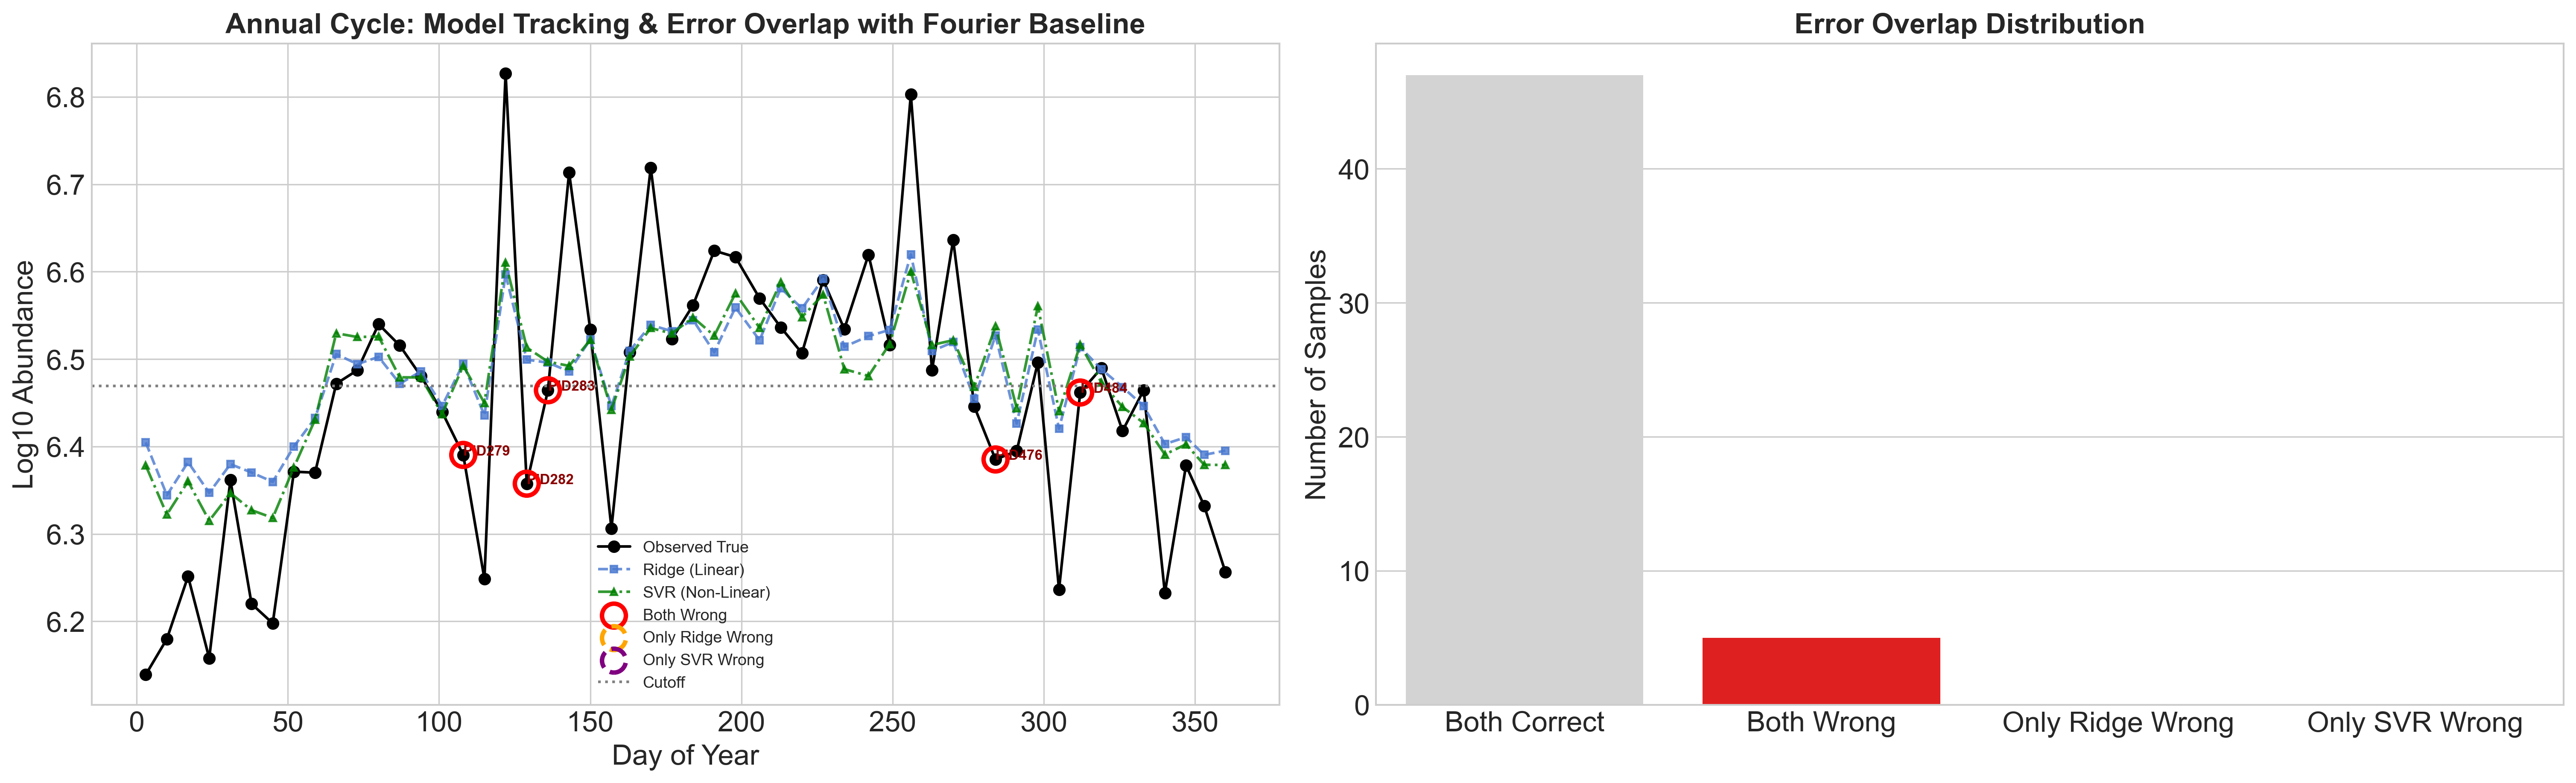

In [13]:
df_compare = main_testing[["SampleID", "DayOfYear", "Season", "LogAbundance"]].copy()
df_compare["TrueClass"] = y_test
df_compare["Ridge_LogPred"] = year_ridge_log_predictions
df_compare["Ridge_Class"] = year_ridge_predictions
df_compare["Ridge_Correct"] = df_compare["Ridge_Class"] == df_compare["TrueClass"]
df_compare["SVR_LogPred"] = svr_log_predictions
df_compare["SVR_Class"] = svr_predictions
df_compare["SVR_Correct"] = df_compare["SVR_Class"] == df_compare["TrueClass"]

def categorize_error(row):
    if not row["Ridge_Correct"] and not row["SVR_Correct"]: return "Both Wrong"
    elif not row["Ridge_Correct"]: return "Only Ridge Wrong"
    elif not row["SVR_Correct"]: return "Only SVR Wrong"
    else: return "Both Correct"

df_compare["ErrorType"] = df_compare.apply(categorize_error, axis=1)
fig1, axes1 = plt.subplots(1, 2, figsize=(20, 6), constrained_layout=True)
ordered = df_compare.sort_values("DayOfYear")

axes1[0].plot(ordered["DayOfYear"], ordered["LogAbundance"], marker="o", color="black", linewidth=1.5, label="Observed True")
axes1[0].plot(ordered["DayOfYear"], ordered["Ridge_LogPred"], marker="s", markersize=4, linestyle="--", alpha=0.8, color="C0", label="Ridge (Linear)")
axes1[0].plot(ordered["DayOfYear"], ordered["SVR_LogPred"], marker="^", markersize=4, linestyle="-.", alpha=0.8, color="green", label="SVR (Non-Linear)")

both_w = ordered[ordered["ErrorType"] == "Both Wrong"]
ridge_w = ordered[ordered["ErrorType"] == "Only Ridge Wrong"]
svr_w = ordered[ordered["ErrorType"] == "Only SVR Wrong"]

axes1[0].scatter(both_w["DayOfYear"], both_w["LogAbundance"], s=180, facecolors="none", edgecolors="red", linewidth=2.5, label="Both Wrong", zorder=5)
axes1[0].scatter(ridge_w["DayOfYear"], ridge_w["LogAbundance"], s=180, facecolors="none", edgecolors="orange", linewidth=2.5, linestyle="--", label="Only Ridge Wrong", zorder=5)
axes1[0].scatter(svr_w["DayOfYear"], svr_w["LogAbundance"], s=180, facecolors="none", edgecolors="purple", linewidth=2.5, linestyle="--", label="Only SVR Wrong", zorder=5)

texts = []
for _, row in ordered[ordered["ErrorType"] != "Both Correct"].iterrows():
    texts.append(axes1[0].text(row["DayOfYear"], row["LogAbundance"], str(row["SampleID"]), fontsize=8, color="darkred", weight="bold"))

axes1[0].axhline(main_cutoff, color="grey", linestyle=":", label="Cutoff")
axes1[0].set(title="Annual Cycle: Model Tracking & Error Overlap with Fourier Baseline", xlabel="Day of Year", ylabel="Log10 Abundance")
axes1[0].legend(fontsize=9, loc="lower center")

error_palette = {
    "Both Correct": "lightgrey", "Both Wrong": "red",
    "Only Ridge Wrong": "orange", "Only SVR Wrong": "purple",
}
sns.countplot(data=df_compare, x="ErrorType", hue="ErrorType", legend=False,
              order=["Both Correct", "Both Wrong", "Only Ridge Wrong", "Only SVR Wrong"], 
              palette=error_palette, ax=axes1[1])
axes1[1].set(title="Error Overlap Distribution", ylabel="Number of Samples", xlabel="")
plt.show()

## 3. Disscussion: Where does the best strategy fail?

In [14]:
wrong_ids = ["PID279", "PID282", "PID283", "PID476", "PID484"]
wrong_mask = main_testing["SampleID"].isin(wrong_ids)
wrong = main_testing.loc[wrong_mask, ["SampleID", "DayOfYear", "LogAbundance"]].copy()
wrong["Distance_from_cutoff"] = np.abs(wrong["LogAbundance"] - main_cutoff)
wrong["Ridge_prediction"] = year_ridge_log_predictions[wrong_mask]
wrong["SVR_prediction"] = svr_log_predictions[wrong_mask]

scaled_features = year_ridge_search.best_estimator_[:-1]
wrong["Nearest_training_distance"] = pairwise_distances(
    scaled_features.transform(main_testing.loc[wrong_mask, ridge_features]),
    scaled_features.transform(main_training[ridge_features]),
).min(axis=1)

display(wrong.sort_values("Distance_from_cutoff", ascending=False).round(3))

,SampleID,DayOfYear,LogAbundance,Distance_from_cutoff,Ridge_prediction,SVR_prediction,Nearest_training_distance
65,PID282,129,6.357,0.112,6.499,6.513,3.080
87,PID476,284,6.385,0.084,6.527,6.537,2.790
62,PID279,108,6.390,0.079,6.495,6.492,2.351
91,PID484,312,6.462,0.007,6.514,6.517,2.799
66,PID283,136,6.464,0.005,6.496,6.497,3.265


**Implication of Misclassifications**

Both models predominantly fail on boundary cases. The `Distance_from_cutoff` for these errors is exceptionally small (mostly < 0.1) which means most prediction error are near the cutoff. PID282 and PID476 show the largest errors among these samples and are also relatively distant from the nearest training observations in the standardized feature space. This suggests that their environmental conditions are less well represented in the training data.

## 4. Final stress test: rotate the held-out year

For each experiment, the cutoff, imputation, scaling and alpha are re-estimated from the two training years.

Model,Full-feature Ridge,Full-feature SVR,Seasonal baseline
Held-out year,,,
1,0.596,0.681,0.660
2,0.904,0.904,0.750
3,0.750,0.615,0.788


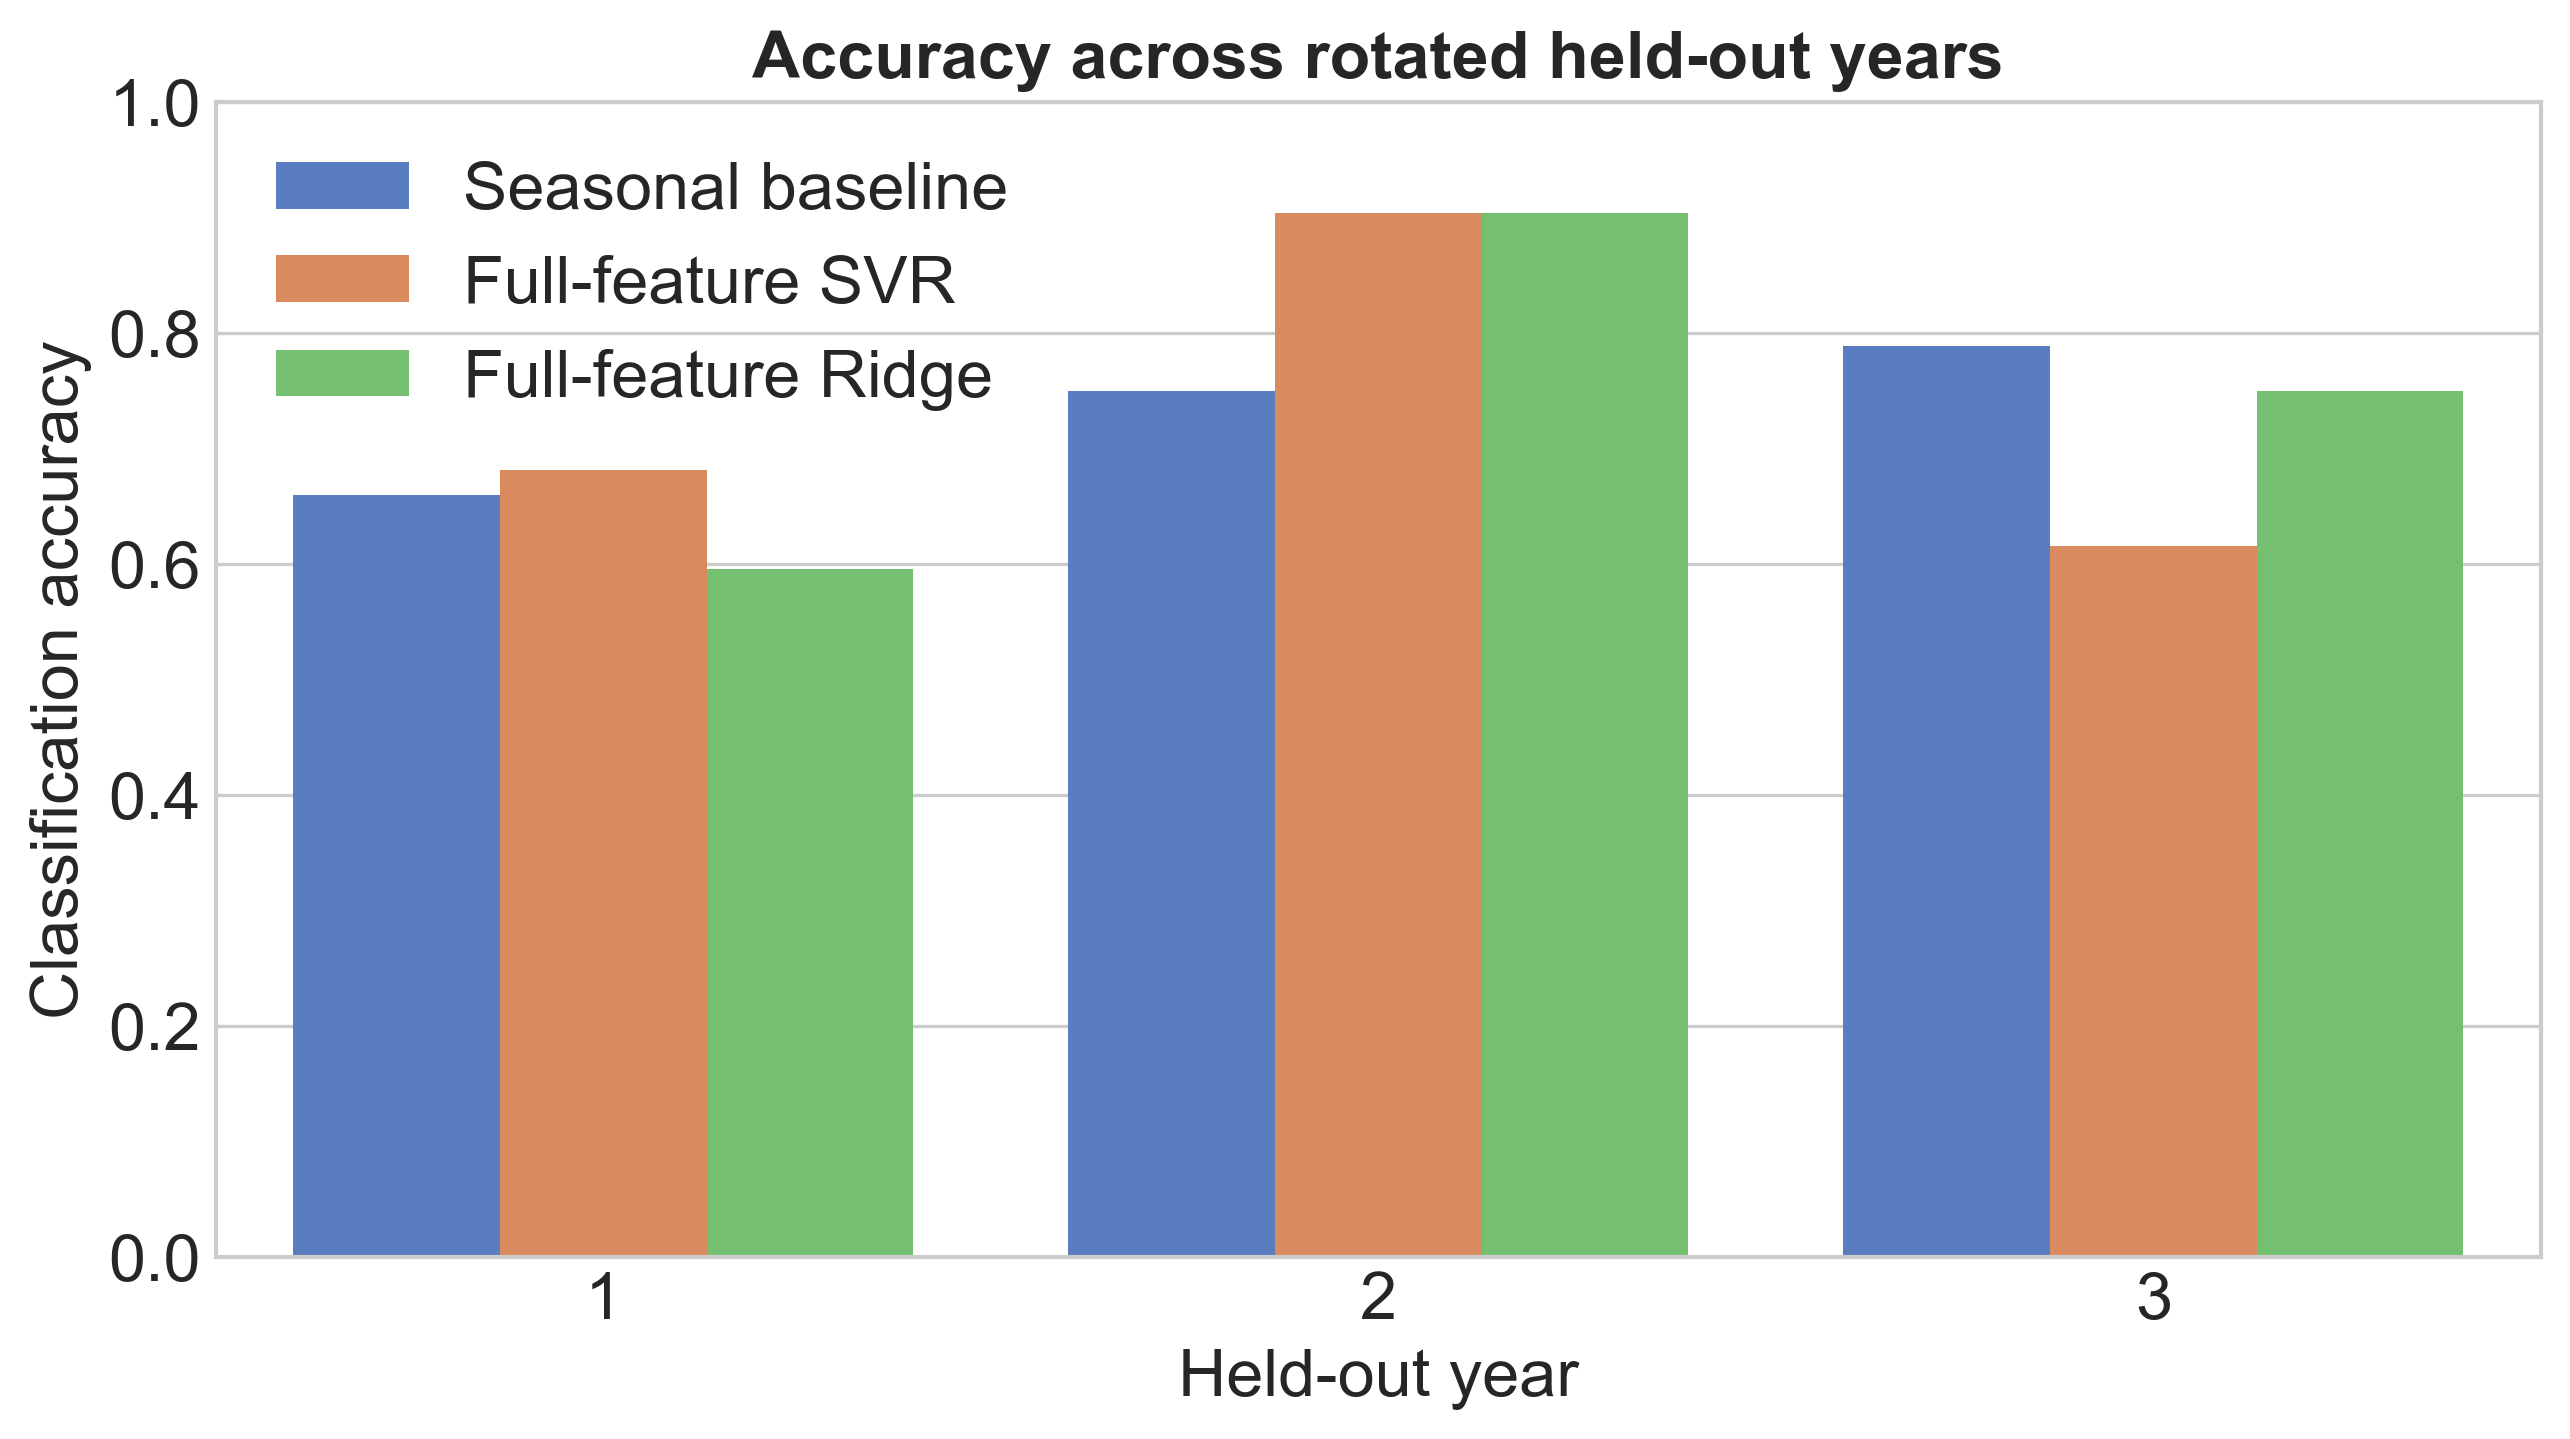

In [15]:
def evaluate_held_out_year(held_out_year):
    training = bacteria[bacteria["Year"] != held_out_year].copy()
    testing = bacteria[bacteria["Year"] == held_out_year].copy()

    cutoff = training["LogAbundance"].mean()
    y_train = target_from_cutoff(training, cutoff)
    y_test = target_from_cutoff(testing, cutoff)

    seasonal_predictions, _ = seasonal_baseline(
        training, testing, y_train
    )

    svr_search, svr_log, svr_class = fit_regression_classifier(
        svr_cv_search(), training, testing, svr_features, cutoff
    )
    ridge_search, ridge_log, ridge_class = fit_regression_classifier(
        ridge_cv_search(), training, testing, ridge_features, cutoff
    )

    results = []
    for model, predictions, log_predictions in [
        ("Seasonal baseline", seasonal_predictions, None),
        ("Full-feature SVR", svr_class, svr_log),
        ("Full-feature Ridge", ridge_class, ridge_log),
    ]:
        results.append({
            "Held-out year": held_out_year,
            "Model": model,
            **classification_metrics(y_test, predictions),
            "Log10 MAE": (
                mean_absolute_error(testing["LogAbundance"], log_predictions)
                if log_predictions is not None else np.nan
            ),
        })

    return results


rotation_results = pd.DataFrame([
    row
    for year in [1, 2, 3]
    for row in evaluate_held_out_year(year)
])

display(
    rotation_results.pivot(
        index="Held-out year",
        columns="Model",
        values="Accuracy",
    ).round(3)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=rotation_results,
    x="Held-out year",
    y="Accuracy",
    hue="Model",
)
plt.ylim(0, 1)
plt.title("Accuracy across rotated held-out years")
plt.ylabel("Classification accuracy")
plt.xlabel("Held-out year")
plt.legend(title="")
plt.show()

**Implication of the rotating held-out-year test**

Model performance varies substantially between years. Both full-feature models perform best when Year 2 is held out, reaching approximately 90% accuracy compared with 75% for the seasonal baseline. For Year 1, SVR provides only a small improvement over the baseline, while Ridge performs worse. For Year 3, the seasonal baseline achieves the highest accuracy, followed by Ridge, whereas SVR performs poorly.

Therefore, environmental measurements improve prediction in Year 2 but do not produce a consistent advantage across all years. This variation suggests that the relationship between bacterial abundance and the measured environmental conditions changes between years. The short three-year record and coarse weekly sampling also limit the models’ ability to learn environmental changes that generalize reliably.

## 5. Conclusions

This analysis tested whether continuous seasonal timing and environmental measurements improve predictions of weekly bacterial abundance. For held-out Year 2, replacing four seasonal categories with Fourier features increased classification accuracy from 75.0% to 80.8%. This shows that exact position within the annual cycle contains useful information about total abundance beyond broad season labels.

Combining temporal and environmental predictors increased Year 2 accuracy to 90.4% for both Ridge and SVR. Most misclassified samples were close to the Low/High cutoff.

However, this improvement was not consistent across the rotated held-out years. SVR only slightly exceeded the seasonal baseline for Year 1, while the seasonal baseline performed best for Year 3. The weaker Year 3 model performance coincided with substantial shifts in several environmental variables. Environmental measurements therefore improved prediction strongly in Year 2, but their relationship with bacterial abundance did not transfer reliably between all years. The competitive seasonal baseline supports the existence of a recurring annual structure, while the usefulness of Fourier features indicates that abundance also varies within those broad seasonal states. The variable performance among years is also consistent with the paper’s observation that the timing of community transitions can shift with environmental conditions.

### References

- Ward, C. S. *et al.* (2017). [Annual community patterns are driven by seasonal switching between closely related marine bacteria](https://www.nature.com/articles/ismej20174). *The ISME Journal*, 11, 1412–1422.
- Course dataset: [PIDweekly_env_data.txt](https://github.com/julianmak/OCES4303_ML_ocean/blob/main/PIDweekly_env_data.txt).
- PICO dataset* (2025): [PICO_biogeochemical_data] collected from Duke Marine Lab dock from 2011-2022. *BCO-DMO* https://www.bco-dmo.org/dataset/956182 